In [89]:
# ============================================================================
# CELL 1: INSTALL DEPENDENCIES & SETUP
# ============================================================================

print(" Starting Zero-Day Attack Detection System Setup...")

# Install required packages
!pip install -q imbalanced-learn scikit-learn tensorflow pandas numpy matplotlib seaborn tqdm joblib

print(" Packages installed successfully!")

# Import libraries
import numpy as np
import pandas as pd
import os
import json
import glob
import time
from sklearn.metrics import roc_curve, precision_recall_curve
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning imports
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Imbalanced learning
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import RandomUnderSampler

# TensorFlow
import tensorflow as tf
from tensorflow import keras

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f" Libraries imported successfully!")
print(f" TensorFlow: {tf.__version__}, NumPy: {np.__version__}")

# Create directories for results
os.makedirs("/content/results", exist_ok=True)
os.makedirs("/content/models", exist_ok=True)
os.makedirs("/content/results/plots", exist_ok=True)

print(" Directories created: /content/results/, /content/models/")

 Starting Zero-Day Attack Detection System Setup...
 Packages installed successfully!
 Libraries imported successfully!
 TensorFlow: 2.19.0, NumPy: 2.0.2
 Directories created: /content/results/, /content/models/


In [90]:
# ============================================================================
# CELL 2: MOUNT GOOGLE DRIVE & FIND DATASET FILES
# ============================================================================

from google.colab import drive

print(" Mounting Google Drive...")
drive.mount('/content/drive')
print(" Google Drive mounted!")

print("\n Searching for CICIDS2017 dataset files...")

# Define the correct path based on your file structure
DATASET_PATH = "/content/drive/MyDrive/CICIDS2017"

# List all CSV files in the directory
if os.path.exists(DATASET_PATH):
    csv_files = glob.glob(os.path.join(DATASET_PATH, "*.csv"))

    if csv_files:
        print(f" Found {len(csv_files)} CSV files in {DATASET_PATH}")

        # Show the files
        print("\n Dataset files found:")
        for i, file_path in enumerate(csv_files, 1):
            filename = os.path.basename(file_path)
            size_mb = os.path.getsize(file_path) / (1024*1024)
            print(f"  {i:2d}. {filename} ({size_mb:.1f} MB)")

        # Sort files by day (Monday to Friday)
        def get_day_order(filename):
            days = {'Monday': 1, 'Tuesday': 2, 'Wednesday': 3, 'Thursday': 4, 'Friday': 5}
            for day, order in days.items():
                if day in filename:
                    return order
            return 99

        DATASET_FILES = sorted(csv_files, key=lambda x: get_day_order(os.path.basename(x)))

        print(f"\nFiles sorted chronologically ({len(DATASET_FILES)} files):")
        for i, file_path in enumerate(DATASET_FILES, 1):
            filename = os.path.basename(file_path)
            print(f"  {i}. {filename}")

        print(f"\n DATASET_FILES variable set successfully!")
    else:
        print(f" No CSV files found in {DATASET_PATH}")
        print("\n Listing directory contents:")
        print(os.listdir(DATASET_PATH))
        DATASET_FILES = []
else:
    print(f" Directory not found: {DATASET_PATH}")
    print("\n Please check the path and update DATASET_PATH variable.")
    DATASET_FILES = []

# If no files found, try alternative search
if not DATASET_FILES:
    print("\n Searching entire Google Drive for CICIDS files...")
    all_files = glob.glob("/content/drive/MyDrive/**/*.csv", recursive=True)

    # Filter for CICIDS files
    cicids_keywords = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'WorkingHours']
    cicids_files = []

    for file_path in all_files:
        filename = os.path.basename(file_path)
        if any(keyword in filename for keyword in cicids_keywords):
            cicids_files.append(file_path)

    if cicids_files:
        DATASET_FILES = sorted(cicids_files, key=lambda x: get_day_order(os.path.basename(x)))
        print(f" Found {len(DATASET_FILES)} CICIDS files in different locations")
    else:
        print(" No CICIDS files found anywhere in Google Drive")
        print("\n Please upload your CICIDS2017 files to Google Drive first.")

 Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Google Drive mounted!

 Searching for CICIDS2017 dataset files...
 Found 8 CSV files in /content/drive/MyDrive/CICIDS2017

 Dataset files found:
   1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (73.6 MB)
   2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (73.3 MB)
   3. Friday-WorkingHours-Morning.pcap_ISCX.csv (55.6 MB)
   4. Monday-WorkingHours.pcap_ISCX.csv (168.7 MB)
   5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (79.3 MB)
   6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (49.6 MB)
   7. Tuesday-WorkingHours.pcap_ISCX.csv (128.8 MB)
   8. Wednesday-workingHours.pcap_ISCX.csv (214.7 MB)

Files sorted chronologically (8 files):
  1. Monday-WorkingHours.pcap_ISCX.csv
  2. Tuesday-WorkingHours.pcap_ISCX.csv
  3. Wednesday-workingHours.pcap_ISCX.csv
  4. Thursday-WorkingHours-Afternoon-Infi

In [91]:
# ============================================================================
# CELL 3: DATA PREPROCESSING CLASS
# ============================================================================

class DataPreprocessor:
    """Handles loading and preprocessing of CICIDS2017 data"""

    def __init__(self):
        self.scaler = None
        self.feature_names = None
        self.label_encoder = LabelEncoder()

    def load_single_file(self, file_path, max_samples=None):
        """Load and preprocess a single CSV file - FIXED VERSION"""
        print(f" Loading {os.path.basename(file_path)}...")

        try:
            # Load the file
            if max_samples:
                df = pd.read_csv(file_path, nrows=max_samples)
            else:
                df = pd.read_csv(file_path)
        except Exception as e:
            print(f" Error loading file: {e}")
            return None, None

        print(f"  Raw data: {len(df):,} samples, {df.shape[1]} features")

        # Clean column names
        df.columns = df.columns.str.strip()

        # Find label column
        label_col = None
        for possible_label in ['Label', 'label', 'Class', 'class', 'target', 'Target']:
            if possible_label in df.columns:
                label_col = possible_label
                break

        if label_col:
            print(f"  Found label column: '{label_col}'")
            y = df[label_col]
            X = df.drop(columns=[label_col])
        else:
            print("  No label column found - treating all as normal")
            X = df
            y = pd.Series(['BENIGN'] * len(df))

        # Handle missing values
        X = X.replace([np.inf, -np.inf], np.nan)
        missing_count = X.isnull().sum().sum()
        if missing_count > 0:
            print(f"  Handling {missing_count:,} missing values...")
            for col in X.columns:
                if X[col].isnull().sum() > 0:
                    X[col].fillna(X[col].median(), inplace=True)

        # CRITICAL FIX: Don't remove constant features here!
        # Save all feature names from first file
        if self.feature_names is None:
            self.feature_names = X.columns.tolist()
            print(f"  Saved {len(self.feature_names)} feature names as reference")
        else:
            # Ensure all files have the same features
            missing_features = set(self.feature_names) - set(X.columns)
            extra_features = set(X.columns) - set(self.feature_names)

            if missing_features:
                print(f"  Warning: {len(missing_features)} features missing from this file")
                for feat in missing_features:
                    X[feat] = 0  # Add with zeros

            if extra_features:
                print(f"  Warning: {len(extra_features)} extra features in this file")
                X = X[self.feature_names]  # Keep only expected features

        # Convert labels to binary: 0=Normal, 1=Attack
        if isinstance(y.iloc[0], str):
            y_binary = (y != 'BENIGN').astype(int)
        else:
            unique_labels = np.unique(y)
            if len(unique_labels) == 2:
                y_binary = y
            else:
                y_binary = (y != 0).astype(int)

        # Print distribution
        attack_count = y_binary.sum()
        normal_count = len(y_binary) - attack_count
        attack_percentage = attack_count / len(y_binary) * 100

        print(f"  Distribution: {normal_count:,} normal, {attack_count:,} attacks ({attack_percentage:.2f}%)")
        print(f"  Final features: {X.shape[1]}")

        return X, y_binary

    def prepare_training_data(self, X, y, test_size=0.3):
        """Prepare training and testing splits"""
        print(f"\n Splitting data (train: {1-test_size:.0%}, test: {test_size:.0%})...")

        # Check if we have attacks
        if y.sum() == 0:
            print("  No attacks in this file - using random split")
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=42
            )
        else:
            # Use stratified split if we have attacks
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=42, stratify=y
            )

        print(f"  Train: {X_train.shape[0]:,} samples ({y_train.sum():,} attacks)")
        print(f"  Test: {X_test.shape[0]:,} samples ({y_test.sum():,} attacks)")

        return X_train, X_test, y_train, y_test

    def normalize_features(self, X_train, X_test, fit_scaler=True):
        """Normalize features using StandardScaler with feature alignment"""
        print(f"\n Normalizing features...")

        # Save feature names if first time
        if self.feature_names is None:
            self.feature_names = X_train.columns.tolist()

        # Align features between train/test and scaler
        X_train = X_train[self.feature_names]
        X_test = X_test[self.feature_names]

        if fit_scaler or self.scaler is None:
            self.scaler = StandardScaler()
            X_train_scaled = self.scaler.fit_transform(X_train)
            print("  Fitted new scaler")
        else:
            X_train_scaled = self.scaler.transform(X_train)
            print("  Used existing scaler")

        X_test_scaled = self.scaler.transform(X_test)

        return X_train_scaled, X_test_scaled

    def balance_classes(self, X_train, y_train, method='smote_tomek'):
        """Handle class imbalance"""
        print(f"\n Balancing classes with {method}...")

        attack_ratio = y_train.sum() / len(y_train)
        print(f"  Original attack ratio: {attack_ratio:.4f} ({y_train.sum()}/{len(y_train)})")

        if attack_ratio == 0:
            print("   No attacks to balance")
            return X_train, y_train

        if attack_ratio >= 0.3:
            print("  Attack ratio already acceptable (≥30%)")
            return X_train, y_train

        try:
            if method == 'smote':
                balancer = SMOTE(random_state=42, sampling_strategy=0.3)
            elif method == 'smote_tomek':
                balancer = SMOTETomek(random_state=42, sampling_strategy=0.3)
            elif method == 'undersample':
                balancer = RandomUnderSampler(random_state=42, sampling_strategy=0.3)
            else:
                print(f"  Unknown method, using SMOTE")
                balancer = SMOTE(random_state=42, sampling_strategy=0.3)

            X_balanced, y_balanced = balancer.fit_resample(X_train, y_train)

            new_ratio = y_balanced.sum() / len(y_balanced)
            print(f"  New attack ratio: {new_ratio:.4f} ({y_balanced.sum()}/{len(y_balanced)})")
            print(f"  Samples: {len(X_train):,} → {len(X_balanced):,}")

            return X_balanced, y_balanced

        except Exception as e:
            print(f" Balancing failed: {e}")
            print("  Using original data")
            return X_train, y_train

print(" DataPreprocessor class defined successfully!")

 DataPreprocessor class defined successfully!


In [101]:
# ============================================================================
# CELL 4: ZERO-DAY DETECTION MODEL CLASS
# ============================================================================

import time
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, precision_recall_curve

class ZeroDayDetector:
    """Main class for zero-day attack detection"""

    def __init__(self):
        self.classifier = None
        self.preprocessor = DataPreprocessor()
        self.results_history = []
        self.file_metrics = {}
        self.optimal_thresholds = {}  # Store optimal thresholds per file

    def find_optimal_threshold(self, y_true, y_proba, method='balanced', target_precision=None):
        """
        Find optimal threshold based on different criteria

        Parameters:
        - method: 'f1' (maximize F1), 'balanced' (balance precision/recall),
                  'high_precision' (prioritize precision), 'custom'
        - target_precision: Target precision value when using 'custom' method
        """
        precision, recall, thresholds = precision_recall_curve(y_true, y_proba)

        if method == 'f1':
            # Maximize F1-score
            f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-7)
            optimal_idx = np.argmax(f1_scores)

        elif method == 'balanced':
            # Balance precision and recall (minimize difference)
            diff = np.abs(precision[:-1] - recall[:-1])
            optimal_idx = np.argmin(diff)

        elif method == 'high_precision':
            # Prioritize precision (minimize false positives)
            # Find threshold where precision >= 0.7
            high_precision_idx = np.where(precision[:-1] >= 0.7)[0]
            if len(high_precision_idx) > 0:
                optimal_idx = high_precision_idx[-1]  # Highest threshold with good precision
            else:
                # Fallback to maximizing precision
                optimal_idx = np.argmax(precision[:-1])

        elif method == 'custom' and target_precision is not None:
            # Target specific precision value
            idx_above_target = np.where(precision[:-1] >= target_precision)[0]
            if len(idx_above_target) > 0:
                optimal_idx = idx_above_target[-1]  # Highest threshold achieving target
            else:
                optimal_idx = np.argmax(precision[:-1])  # Best possible
        else:
            # Default to 0.5
            return 0.5

        optimal_threshold = thresholds[optimal_idx]
        return max(0.01, min(0.99, optimal_threshold))  # Clamp between 0.01 and 0.99

    def analyze_threshold_sensitivity(self, y_true, y_proba):
        """Analyze how different thresholds affect metrics"""
        thresholds = np.arange(0.1, 1.0, 0.1)
        results = []

        print("\n" + "="*70)
        print("THRESHOLD SENSITIVITY ANALYSIS")
        print("="*70)
        print(f"{'Threshold':<10} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'TP':<8} {'FP':<8} {'FN':<8}")
        print("-"*70)

        for thresh in thresholds:
            y_pred = (y_proba >= thresh).astype(int)
            precision = precision_score(y_true, y_pred, zero_division=0)
            recall = recall_score(y_true, y_pred, zero_division=0)
            f1 = f1_score(y_true, y_pred, zero_division=0)

            # Calculate TP, FP, FN
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

            results.append({
                'threshold': thresh,
                'precision': precision,
                'recall': recall,
                'f1': f1,
                'tp': tp,
                'fp': fp,
                'fn': fn
            })

            print(f"{thresh:<10.2f} {precision:<12.4f} {recall:<12.4f} {f1:<12.4f} "
                  f"{tp:<8} {fp:<8} {fn:<8}")

        print("="*70)

        # Find best thresholds by different criteria
        results_df = pd.DataFrame(results)

        # Best F1
        best_f1_idx = results_df['f1'].idxmax()
        best_f1 = results_df.loc[best_f1_idx]

        # Best balanced (precision ≈ recall)
        results_df['precision_recall_diff'] = np.abs(results_df['precision'] - results_df['recall'])
        best_balanced_idx = results_df['precision_recall_diff'].idxmin()
        best_balanced = results_df.loc[best_balanced_idx]

        # Best for high precision (precision > 0.8)
        high_precision = results_df[results_df['precision'] >= 0.8]
        if len(high_precision) > 0:
            best_high_precision = high_precision.iloc[-1]  # Highest threshold with precision >= 0.8
        else:
            best_high_precision = None

        print("\n📊 RECOMMENDED THRESHOLDS:")
        print(f"  Best F1-Score: {best_f1['threshold']:.2f} (F1={best_f1['f1']:.4f}, "
              f"P={best_f1['precision']:.4f}, R={best_f1['recall']:.4f})")
        print(f"  Most Balanced: {best_balanced['threshold']:.2f} "
              f"(P={best_balanced['precision']:.4f}, R={best_balanced['recall']:.4f})")

        if best_high_precision is not None:
            print(f"  High Precision: {best_high_precision['threshold']:.2f} "
                  f"(P={best_high_precision['precision']:.4f}, R={best_high_precision['recall']:.4f})")

        return results_df

    def initialize_classifier(self, input_dim):
        """Initialize Random Forest classifier with balanced weights"""
        print(f"\n Initializing Random Forest Classifier...")

        self.classifier = RandomForestClassifier(
            n_estimators=150,  # Increased from 100
            max_depth=20,
            min_samples_split=15,  # Increased for more generalization
            min_samples_leaf=8,    # Increased to reduce overfitting
            class_weight='balanced_subsample',  # Better for imbalanced data
            max_features='sqrt',    # Use sqrt(n_features) for diversity
            bootstrap=True,
            oob_score=True,         # Out-of-bag score for validation
            random_state=42,
            n_jobs=-1,
            verbose=0
        )

        print(f" Random Forest initialized with {input_dim} features")
        print("  - 150 trees, max depth 20")
        print("  - Balanced subsample class weights")
        print("  - Out-of-bag validation enabled")
        print("  - Parallel processing enabled")

    def calculate_metrics(self, y_true, y_pred, y_pred_proba=None, threshold=0.5):
        """Calculate all performance metrics"""
        metrics = {
            'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'f1': f1_score(y_true, y_pred, zero_division=0),
            'threshold_used': threshold
        }

        # AUC-ROC if probability scores available
        if y_pred_proba is not None:
            try:
                metrics['auc_roc'] = roc_auc_score(y_true, y_pred_proba)

                # Calculate ROC curve for threshold analysis
                fpr, tpr, roc_thresholds = roc_curve(y_true, y_pred_proba)
                metrics['roc_curve'] = {'fpr': fpr.tolist(), 'tpr': tpr.tolist()}

                # Calculate Precision-Recall curve
                precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_true, y_pred_proba)
                metrics['pr_curve'] = {
                    'precision': precision_curve.tolist(),
                    'recall': recall_curve.tolist()
                }

            except Exception as e:
                print(f"  Warning: Could not calculate ROC/AUC: {e}")
                metrics['auc_roc'] = 0.5
        else:
            metrics['auc_roc'] = 0.5

        # Confusion matrix details
        cm = confusion_matrix(y_true, y_pred)
        if cm.size == 4:
            tn, fp, fn, tp = cm.ravel()
            metrics.update({
                'true_negatives': int(tn),
                'false_positives': int(fp),
                'false_negatives': int(fn),
                'true_positives': int(tp),
                'detection_rate': tp / (tp + fn) if (tp + fn) > 0 else 0,
                'false_positive_rate': fp / (fp + tn) if (fp + tn) > 0 else 0,
                'false_negative_rate': fn / (fn + tp) if (fn + tp) > 0 else 0,
                'true_negative_rate': tn / (tn + fp) if (tn + fp) > 0 else 0
            })

            # Calculate additional metrics
            metrics['false_alarm_ratio'] = fp / (tp + fp) if (tp + fp) > 0 else 0
            metrics['critical_success_index'] = tp / (tp + fn + fp) if (tp + fn + fp) > 0 else 0

        return metrics

    def train_on_file(self, file_path, file_index, max_samples=50000):
        """Train on a single file with threshold optimization"""
        print(f"\n{'='*80}")
        print(f" [{file_index}] PROCESSING: {os.path.basename(file_path)}")
        print(f"{'='*80}")

        # 1. Load and preprocess
        X, y = self.preprocessor.load_single_file(file_path, max_samples)

        if X is None or y.sum() == 0:
            print("   No data or no attacks - skipping")
            return None

        # 2. Split data
        X_train, X_test, y_train, y_test = self.preprocessor.prepare_training_data(X, y)

        # 3. Normalize features
        fit_scaler = (file_index == 1) or (self.preprocessor.scaler is None)
        X_train_scaled, X_test_scaled = self.preprocessor.normalize_features(
            X_train, X_test, fit_scaler=fit_scaler
        )

        # 4. Balance classes (CRITICAL STEP)
        X_train_balanced, y_train_balanced = self.preprocessor.balance_classes(
            X_train_scaled, y_train, method='smote_tomek'
        )

        # 5. Initialize or use existing classifier
        if self.classifier is None:
            self.initialize_classifier(X_train_balanced.shape[1])

        # 6. Train classifier
        print(f"\nTraining Random Forest...")
        start_time = time.time()
        self.classifier.fit(X_train_balanced, y_train_balanced)
        training_time = time.time() - start_time
        print(f"  Training complete in {training_time:.2f} seconds")

        # Get OOB score if available
        if hasattr(self.classifier, 'oob_score_'):
            print(f"  Out-of-bag score: {self.classifier.oob_score_:.4f}")

        # 7. Threshold optimization and evaluation
        print(f"\n{'='*60}")
        print("THRESHOLD OPTIMIZATION PHASE")
        print("="*60)

        # Get probability scores
        y_pred_proba = self.classifier.predict_proba(X_test_scaled)[:, 1]

        # Analyze threshold sensitivity
        threshold_analysis = self.analyze_threshold_sensitivity(y_test, y_pred_proba)

        # Let user choose threshold strategy
        print("\n📈 SELECT THRESHOLD STRATEGY:")
        print("  1. Maximize F1-Score")
        print("  2. Balance Precision and Recall")
        print("  3. Prioritize High Precision (reduce false alarms)")
        print("  4. Use default (0.5)")

        # Auto-select based on previous performance
        if file_index > 1 and self.results_history:
            # Check if previous file had low precision
            prev_metrics = self.results_history[-1]['metrics']
            if prev_metrics.get('precision', 0) < 0.6:
                choice = 3  # Prioritize high precision
                print(f"  Auto-selecting: High Precision (previous precision was low: {prev_metrics['precision']:.4f})")
            elif prev_metrics.get('f1', 0) < 0.7:
                choice = 1  # Maximize F1
                print(f"  Auto-selecting: Maximize F1 (previous F1 was low: {prev_metrics['f1']:.4f})")
            else:
                choice = 2  # Balanced
                print("  Auto-selecting: Balanced Precision/Recall")
        else:
            choice = 2  # Default to balanced for first file

        # Map choice to method
        method_map = {1: 'f1', 2: 'balanced', 3: 'high_precision', 4: 'default'}
        method = method_map.get(choice, 'balanced')

        # Find optimal threshold
        if method == 'default':
            optimal_threshold = 0.5
        else:
            optimal_threshold = self.find_optimal_threshold(y_test, y_pred_proba, method=method)

        print(f"\n✅ Selected threshold: {optimal_threshold:.4f} (method: {method})")

        # Make predictions with optimal threshold
        y_pred = (y_pred_proba >= optimal_threshold).astype(int)

        # Store optimal threshold
        self.optimal_thresholds[file_index] = optimal_threshold

        # Calculate metrics
        metrics = self.calculate_metrics(y_test, y_pred, y_pred_proba, optimal_threshold)

        # 8. Feature importance analysis
        print(f"\n{'='*60}")
        print("FEATURE IMPORTANCE ANALYSIS")
        print("="*60)

        if hasattr(self.classifier, 'feature_importances_'):
            feature_importances = self.classifier.feature_importances_

            # Get top 10 features
            feature_names = X.columns.tolist()
            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance': feature_importances
            }).sort_values('importance', ascending=False).head(10)

            print("\nTop 10 Most Important Features:")
            for idx, row in importance_df.iterrows():
                print(f"  {row['feature']}: {row['importance']:.4f}")

            metrics['top_features'] = importance_df.to_dict('records')

        # 9. Save results
        result = {
            'file': os.path.basename(file_path),
            'file_index': file_index,
            'train_samples': X_train.shape[0],
            'test_samples': X_test.shape[0],
            'train_attacks': int(y_train.sum()),
            'test_attacks': int(y_test.sum()),
            'attack_ratio': y_train.sum() / len(y_train),
            'training_time': training_time,
            'threshold_method': method,
            'optimal_threshold': optimal_threshold,
            'metrics': metrics,
            'confusion_matrix': confusion_matrix(y_test, y_pred).tolist(),
            'timestamp': datetime.now().isoformat()
        }

        self.results_history.append(result)
        self.file_metrics[file_index] = metrics

        # 10. Display results
        self._display_results(result)

        # 11. Save checkpoint
        self._save_checkpoint(file_index)

        return result

    def _display_results(self, result):
        """Display training results with enhanced visualization"""
        metrics = result['metrics']

        print(f"\n{'='*60}")
        print(f" RESULTS FOR {result['file']}")
        print("="*60)

        # Create a formatted metrics table
        print(f"\n📊 PERFORMANCE METRICS (Threshold: {result['optimal_threshold']:.4f}):")
        print("-"*60)
        print(f"{'Metric':<20} {'Value':<10} {'Status':<15}")
        print("-"*60)

        # Define status levels
        def get_status(value, metric_name):
            if metric_name == 'accuracy':
                if value >= 0.95: return "Excellent ✅"
                elif value >= 0.90: return "Good ✓"
                elif value >= 0.80: return "Fair ~"
                else: return "Poor ✗"

            elif metric_name == 'precision':
                if value >= 0.90: return "Excellent ✅"
                elif value >= 0.80: return "Good ✓"
                elif value >= 0.70: return "Fair ~"
                else: return "Poor ✗"

            elif metric_name == 'recall':
                if value >= 0.95: return "Excellent ✅"
                elif value >= 0.90: return "Good ✓"
                elif value >= 0.80: return "Fair ~"
                else: return "Poor ✗"

            elif metric_name == 'f1':
                if value >= 0.90: return "Excellent ✅"
                elif value >= 0.80: return "Good ✓"
                elif value >= 0.70: return "Fair ~"
                else: return "Poor ✗"

            elif metric_name == 'auc_roc':
                if value >= 0.95: return "Excellent ✅"
                elif value >= 0.90: return "Good ✓"
                elif value >= 0.80: return "Fair ~"
                else: return "Poor ✗"

            return ""

        # Display each metric
        for metric_name in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
            value = metrics.get(metric_name, 0)
            status = get_status(value, metric_name)
            print(f"{metric_name.capitalize():<20} {value:<10.4f} {status:<15}")

        # Display confusion matrix summary
        if 'true_positives' in metrics:
            print(f"\n🔍 DETECTION SUMMARY:")
            print(f"  True Positives (Attacks caught):  {metrics['true_positives']}")
            print(f"  False Negatives (Attacks missed): {metrics['false_negatives']}")
            print(f"  False Positives (False alarms):   {metrics['false_positives']}")
            print(f"  True Negatives (Correct normals): {metrics['true_negatives']}")
            print(f"  Detection Rate:  {metrics.get('detection_rate', 0):.2%}")
            print(f"  False Alarm Rate: {metrics.get('false_positive_rate', 0):.2%}")

        # Overall assessment
        print(f"\n💡 RECOMMENDATION:")
        f1_score = metrics.get('f1', 0)
        precision = metrics.get('precision', 0)
        recall = metrics.get('recall', 0)

        if precision < 0.6 and recall > 0.9:
            print("  ⚠️  Too many false alarms! Consider increasing threshold.")
        elif precision > 0.8 and recall < 0.6:
            print("  ⚠️  Missing too many attacks! Consider decreasing threshold.")
        elif f1_score >= 0.8:
            print("  ✅ Good balance between precision and recall.")
        elif f1_score >= 0.7:
            print("  ⚠️  Acceptable but needs improvement.")
        else:
            print("  ❌ Needs significant improvement.")

        print("="*60)

    def _save_checkpoint(self, file_index):
        """Save model checkpoint"""
        import joblib

        checkpoint_dir = f"/content/models/checkpoint_{file_index}"
        os.makedirs(checkpoint_dir, exist_ok=True)

        # Save classifier
        if self.classifier is not None:
            joblib.dump(self.classifier, f"{checkpoint_dir}/classifier.joblib")

        # Save preprocessor
        joblib.dump(self.preprocessor, f"{checkpoint_dir}/preprocessor.joblib")

        # Save results
        results_file = f"/content/results/progressive_results_{file_index}.json"
        with open(results_file, 'w') as f:
            json.dump(self.results_history, f, indent=2)

        # Save optimal thresholds
        thresholds_file = f"{checkpoint_dir}/optimal_thresholds.json"
        with open(thresholds_file, 'w') as f:
            json.dump(self.optimal_thresholds, f, indent=2)

        print(f" Checkpoint saved: {checkpoint_dir}")

    # ADD THESE MISSING METHODS:
    def run_progressive_training(self, file_paths, max_samples_per_file=50000):
        """Run progressive training on multiple files"""
        print(f"\n{'='*80}")
        print(f" STARTING PROGRESSIVE TRAINING")
        print(f"Processing {len(file_paths)} files")
        print(f"{'='*80}")

        all_results = []

        for i, file_path in enumerate(file_paths, 1):
            try:
                print(f"\n{'='*80}")
                print(f" FILE {i}/{len(file_paths)}")
                print(f"{'='*80}")

                result = self.train_on_file(file_path, i, max_samples_per_file)
                if result:
                    all_results.append(result)

                    # Save progress summary
                    self._save_progress_summary(i)

            except Exception as e:
                print(f" Error processing file {i}: {e}")
                import traceback
                traceback.print_exc()
                print("Continuing with next file...")
                continue

        # Generate final report
        if all_results:
            self._generate_final_report(all_results)
        else:
            print(" No results generated from training")

        return all_results

    def _save_progress_summary(self, current_file):
        """Save progress summary"""
        summary = {
            'timestamp': datetime.now().isoformat(),
            'current_file': current_file,
            'total_files': len(DATASET_FILES),
            'results': self.results_history,
            'total_samples': sum([r['train_samples'] + r['test_samples'] for r in self.results_history]),
            'total_attacks': sum([r['train_attacks'] + r['test_attacks'] for r in self.results_history]),
            'optimal_thresholds': self.optimal_thresholds
        }

        summary_file = f"/content/results/progress_summary_{current_file}.json"
        with open(summary_file, 'w') as f:
            json.dump(summary, f, indent=2)

    def _generate_final_report(self, all_results):
        """Generate comprehensive final report"""
        print(f"\n{'='*80}")
        print(" GENERATING FINAL REPORT")
        print(f"{'='*80}")

        if not all_results:
            print(" No results to report")
            return

        final_result = all_results[-1]
        metrics = final_result['metrics']

        # Calculate overall statistics
        total_files = len(all_results)
        total_samples = sum([r['train_samples'] + r['test_samples'] for r in all_results])
        total_attacks = sum([r['train_attacks'] + r['test_attacks'] for r in all_results])

        # Performance assessment
        assessment = self._assess_performance(metrics)

        # Calculate average metrics across all files
        avg_metrics = {}
        if all_results:
            for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
                values = [r['metrics'].get(metric, 0) for r in all_results]
                avg_metrics[f'avg_{metric}'] = np.mean(values)

        report = {
            'timestamp': datetime.now().isoformat(),
            'total_files_processed': total_files,
            'total_samples': total_samples,
            'total_attacks': total_attacks,
            'attack_percentage': total_attacks / total_samples * 100 if total_samples > 0 else 0,
            'final_performance': metrics,
            'average_performance': avg_metrics,
            'optimal_thresholds': self.optimal_thresholds,
            'performance_assessment': assessment,
            'recommendations': self._generate_recommendations(metrics),
            'all_results': all_results
        }

        # Save report
        report_file = "/content/results/final_report.json"
        with open(report_file, 'w') as f:
            json.dump(report, f, indent=2)

        # Display report
        print(f"\n FINAL PERFORMANCE ASSESSMENT")
        print(f"  Level: {assessment['level']}")
        print(f"  Message: {assessment['message']}")
        print(f"  Deployable: {'YES' if assessment['deployable'] else 'NO'}")

        print(f"\n FINAL METRICS (File {total_files}):")
        print(f"  Accuracy:  {metrics['accuracy']:.4f}")
        print(f"  Precision: {metrics['precision']:.4f}")
        print(f"  Recall:    {metrics['recall']:.4f}")
        print(f"  F1-Score:  {metrics['f1']:.4f}")
        print(f"  AUC-ROC:   {metrics['auc_roc']:.4f}")
        print(f"  Threshold: {final_result['optimal_threshold']:.4f}")

        if 'true_positives' in metrics:
            print(f"\n DETECTION SUMMARY:")
            print(f"  Attacks Detected: {metrics['true_positives']}/{metrics['true_positives'] + metrics['false_negatives']}")
            print(f"  Detection Rate:   {metrics['detection_rate']:.2%}")
            print(f"  False Alarm Rate: {metrics.get('false_positive_rate', 0):.2%}")

        print(f"\n AVERAGE PERFORMANCE (All {total_files} files):")
        for metric, value in avg_metrics.items():
            print(f"  {metric.replace('avg_', '').capitalize()}: {value:.4f}")

        print(f"\n OPTIMAL THRESHOLDS:")
        for file_idx, threshold in self.optimal_thresholds.items():
            print(f"  File {file_idx}: {threshold:.4f}")

        print(f"\n OVERALL STATISTICS:")
        print(f"  Files Processed: {total_files}")
        print(f"  Total Samples:   {total_samples:,}")
        print(f"  Total Attacks:   {total_attacks:,}")
        print(f"  Attack Ratio:    {total_attacks/total_samples*100:.2f}%")

        print(f"\n Final report saved: {report_file}")

    def _assess_performance(self, metrics):
        """Honestly assess system performance"""
        precision = metrics['precision']
        recall = metrics['recall']
        f1 = metrics['f1']
        auc = metrics['auc_roc']

        # Critical failure check
        if precision == 0 and recall == 0:
            return {
                'level': 'CRITICAL FAILURE',
                'message': 'System detects NO attacks. Completely non-functional.',
                'deployable': False
            }

        # Poor performance
        if f1 < 0.3 or auc < 0.6:
            return {
                'level': 'POOR',
                'message': f'Minimal detection capability (F1={f1:.3f}, AUC={auc:.3f})',
                'deployable': False
            }

        # Moderate performance
        if f1 < 0.7 or auc < 0.8:
            return {
                'level': 'MODERATE',
                'message': f'Acceptable but needs improvement (F1={f1:.3f})',
                'deployable': False
            }

        # Good performance
        if f1 < 0.9:
            return {
                'level': 'GOOD',
                'message': f'Effective detection system (F1={f1:.3f})',
                'deployable': True
            }

        # Excellent performance
        return {
            'level': 'EXCELLENT',
            'message': f'Highly effective detection (F1={f1:.3f})',
            'deployable': True
        }

    def _generate_recommendations(self, metrics):
        """Generate actionable recommendations"""
        recommendations = []

        if metrics['precision'] == 0 and metrics['recall'] == 0:
            recommendations = [
                "DO NOT DEPLOY - System detects NO attacks",
                "Fix class imbalance with aggressive SMOTE (sampling_strategy=0.5)",
                "Verify data preprocessing and labeling",
                "Test with synthetic attack data first"
            ]
        elif metrics['precision'] < 0.5:
            recommendations = [
                f"Current precision is low ({metrics['precision']:.2%}) - too many false alarms",
                f"Try increasing threshold (current: {metrics.get('threshold_used', 0.5):.3f})",
                "Add more diverse normal traffic samples",
                "Implement ensemble methods with different thresholds",
                "Consider post-processing rules to filter false positives"
            ]
        elif metrics['recall'] < 0.5:
            recommendations = [
                f"Current recall is low ({metrics['recall']:.2%}) - missing too many attacks",
                f"Try decreasing threshold (current: {metrics.get('threshold_used', 0.5):.3f})",
                "Collect more attack samples for training",
                "Use anomaly detection as secondary check",
                "Implement alert severity levels"
            ]
        elif metrics['precision'] < 0.7:
            recommendations = [
                f"Precision needs improvement ({metrics['precision']:.2%})",
                f"Consider increasing threshold from {metrics.get('threshold_used', 0.5):.3f}",
                "Review feature importance and remove noisy features",
                "Implement voting ensemble for consensus detection"
            ]
        elif metrics['recall'] < 0.7:
            recommendations = [
                f"Recall needs improvement ({metrics['recall']:.2%})",
                f"Consider decreasing threshold from {metrics.get('threshold_used', 0.5):.3f}",
                "Add more attack variants to training data",
                "Implement multi-stage detection pipeline"
            ]
        else:
            recommendations = [
                f"Good performance! Current threshold: {metrics.get('threshold_used', 0.5):.3f}",
                "Monitor precision/recall metrics continuously",
                "Implement rolling retraining with new data",
                "Establish performance degradation alerts",
                "Conduct periodic penetration testing"
            ]

        return recommendations

print("ZeroDayDetector class defined successfully!")

ZeroDayDetector class defined successfully!


In [102]:
# ============================================================================
# CELL 5: RUN THE TRAINING
# ============================================================================

# Check if we have dataset files
if 'DATASET_FILES' in globals() and len(DATASET_FILES) > 0:
    print(f" Found {len(DATASET_FILES)} dataset files")

    # Show files to process
    print(f"\n Processing first 3 files in chronological order:")
    for i, file_path in enumerate(DATASET_FILES[:8], 1):
        filename = os.path.basename(file_path)
        print(f"  {i}. {filename}")

    # Create detector
    print(f"\n Creating Zero-Day Detection System...")
    detector = ZeroDayDetector()

    # Run progressive training on first 3 files
    print(f"\n{'='*80}")
    print(" STARTING TRAINING")
    print(f"{'='*80}")

    results = detector.run_progressive_training(
        DATASET_FILES[:8],  # Process Monday, Tuesday, Wednesday
        max_samples_per_file=100000
    )

    if results:
        print(f"\n{'='*80}")
        print(" TRAINING COMPLETED SUCCESSFULLY!")
        print(f"{'='*80}")

        # Show summary
        print(f"\n TRAINING SUMMARY:")
        print(f"  Files Processed: {len(results)}")
        print(f"  Total Samples: {sum([r['train_samples'] + r['test_samples'] for r in results]):,}")
        print(f"  Total Attacks: {sum([r['train_attacks'] + r['test_attacks'] for r in results]):,}")

        # Show final metrics
        final_result = results[-1]
        final_metrics = final_result['metrics']

        print(f"\n FINAL MODEL PERFORMANCE:")
        print(f"  Accuracy:  {final_metrics['accuracy']:.4f}")
        print(f"  Precision: {final_metrics['precision']:.4f}")
        print(f"  Recall:    {final_metrics['recall']:.4f}")
        print(f"  F1-Score:  {final_metrics['f1']:.4f}")
        print(f"  AUC-ROC:   {final_metrics['auc_roc']:.4f}")

        if final_metrics['precision'] == 0 and final_metrics['recall'] == 0:
            print(f"\n CRITICAL ISSUE: Model detects NO attacks!")
            print("   The system is currently non-functional.")
        elif final_metrics['f1'] < 0.5:
            print(f"\n  WARNING: Poor detection capability")
            print("   Needs significant improvement before deployment")
        else:
            print(f"\n ACCEPTABLE: Model has basic detection capability")

        print(f"\nResults saved in: /content/results/")
        print(f" Models saved in: /content/models/")

    else:
        print(f"\n Training failed or produced no results")

else:
    print(" No dataset files found!")
    print("\n Please run Cell 2 first to mount Google Drive and find files.")

 Found 8 dataset files

 Processing first 3 files in chronological order:
  1. Monday-WorkingHours.pcap_ISCX.csv
  2. Tuesday-WorkingHours.pcap_ISCX.csv
  3. Wednesday-workingHours.pcap_ISCX.csv
  4. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  5. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  6. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  7. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  8. Friday-WorkingHours-Morning.pcap_ISCX.csv

 Creating Zero-Day Detection System...

 STARTING TRAINING

 STARTING PROGRESSIVE TRAINING
Processing 8 files

 FILE 1/8

 [1] PROCESSING: Monday-WorkingHours.pcap_ISCX.csv
 Loading Monday-WorkingHours.pcap_ISCX.csv...
  Raw data: 100,000 samples, 79 features
  Found label column: 'Label'
  Handling 188 missing values...
  Saved 78 feature names as reference
  Distribution: 100,000 normal, 0 attacks (0.00%)
  Final features: 78
   No data or no attacks - skipping

 FILE 2/8

 [2] PROCESSING: Tuesday-WorkingHours.pc

In [103]:
# ============================================================================
# CELL 6: GENERATE VISUALIZATIONS
# ============================================================================

def generate_visualizations():
    """Generate performance visualization plots"""
    print(f"\n{'='*80}")
    print(" GENERATING VISUALIZATIONS")
    print(f"{'='*80}")

    # Check if results exist
    results_files = glob.glob("/content/results/*.json")
    if not results_files:
        print(" No results files found")
        return

    # Load latest results
    try:
        latest_file = max(results_files, key=os.path.getctime)
        with open(latest_file, 'r') as f:
            results_data = json.load(f)
    except:
        print(" Could not load results")
        return

    if 'all_results' not in results_data:
        print(" No results data in file")
        return

    results = results_data['all_results']
    if not results:
        print(" No results to visualize")
        return

    print(f" Loaded {len(results)} results")

    # Create figure with subplots
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # 1. Performance Metrics Progression
    ax1 = axes[0, 0]
    files = [f"File {r['file_index']}" for r in results]
    metrics = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
    metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']

    x = range(len(files))
    for i, metric in enumerate(metrics):
        values = [r['metrics'][metric] for r in results]
        ax1.plot(x, values, marker='o', linewidth=2, markersize=8, label=metric_names[i])

    ax1.set_xlabel('Training File', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Score', fontsize=12, fontweight='bold')
    ax1.set_title('Performance Metrics Progression', fontsize=14, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels([f"F{i+1}" for i in x])
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)

    # 2. Attack Distribution
    ax2 = axes[0, 1]
    files = [f"F{r['file_index']}" for r in results]
    normal_samples = [r['train_samples'] - r['train_attacks'] for r in results]
    attack_samples = [r['train_attacks'] for r in results]

    x = range(len(files))
    width = 0.6
    ax2.bar(x, normal_samples, width, label='Normal', color='skyblue', alpha=0.8)
    ax2.bar(x, attack_samples, width, bottom=normal_samples, label='Attack', color='salmon', alpha=0.8)

    ax2.set_xlabel('Training File', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Samples', fontsize=12, fontweight='bold')
    ax2.set_title('Attack vs Normal Distribution', fontsize=14, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(files)
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3, axis='y')

    # 3. Detection Results
    ax3 = axes[0, 2]
    if 'true_positives' in results[0]['metrics']:
        detected = [r['metrics']['true_positives'] for r in results]
        missed = [r['metrics']['false_negatives'] for r in results]

        x = range(len(files))
        ax3.bar(x, detected, width, label='Detected', color='green', alpha=0.8)
        ax3.bar(x, missed, width, bottom=detected, label='Missed', color='red', alpha=0.8)

        ax3.set_xlabel('Training File', fontsize=12, fontweight='bold')
        ax3.set_ylabel('Attack Samples', fontsize=12, fontweight='bold')
        ax3.set_title('Attack Detection Results', fontsize=14, fontweight='bold')
        ax3.set_xticks(x)
        ax3.set_xticklabels(files)
        ax3.legend(loc='upper right')
        ax3.grid(True, alpha=0.3, axis='y')
    else:
        ax3.text(0.5, 0.5, 'Detection data not available',
                ha='center', va='center', fontsize=12, transform=ax3.transAxes)
        ax3.set_title('Attack Detection Results', fontsize=14, fontweight='bold')

    # 4. Final Confusion Matrix
    ax4 = axes[1, 0]
    final_result = results[-1]
    if 'confusion_matrix' in final_result:
        cm = np.array(final_result['confusion_matrix'])
        sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax4,
                   xticklabels=['Predicted Normal', 'Predicted Attack'],
                   yticklabels=['Actual Normal', 'Actual Attack'])
        ax4.set_title('Final Model Confusion Matrix', fontsize=14, fontweight='bold')
        ax4.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
        ax4.set_ylabel('Actual Label', fontsize=12, fontweight='bold')
    else:
        ax4.text(0.5, 0.5, 'Confusion matrix not available',
                ha='center', va='center', fontsize=12, transform=ax4.transAxes)
        ax4.set_title('Final Model Confusion Matrix', fontsize=14, fontweight='bold')

    # 5. Training Time Analysis
    ax5 = axes[1, 1]
    training_times = [r.get('training_time', 0) for r in results]
    inference_times = [r.get('inference_time', 0) for r in results]

    x = range(len(files))
    width = 0.35
    ax5.bar([i - width/2 for i in x], training_times, width,
            label='Training Time', color='orange', alpha=0.8)
    ax5.bar([i + width/2 for i in x], inference_times, width,
            label='Inference Time', color='purple', alpha=0.8)

    ax5.set_xlabel('Training File', fontsize=12, fontweight='bold')
    ax5.set_ylabel('Time (seconds)', fontsize=12, fontweight='bold')
    ax5.set_title('Training & Inference Time Analysis', fontsize=14, fontweight='bold')
    ax5.set_xticks(x)
    ax5.set_xticklabels(files)
    ax5.legend(loc='upper right')
    ax5.grid(True, alpha=0.3, axis='y')

    # 6. Model Performance Summary
    ax6 = axes[1, 2]
    final_metrics = final_result['metrics']
    summary_metrics = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
    summary_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
    summary_values = [final_metrics[metric] for metric in summary_metrics]

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    bars = ax6.barh(summary_names, summary_values, color=colors, alpha=0.8)

    # Add value labels
    for bar, value in zip(bars, summary_values):
        width = bar.get_width()
        ax6.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                f'{value:.3f}', va='center', fontsize=10, fontweight='bold')

    ax6.set_xlabel('Score', fontsize=12, fontweight='bold')
    ax6.set_title('Final Model Performance Summary', fontsize=14, fontweight='bold')
    ax6.set_xlim(0, 1.1)
    ax6.grid(True, alpha=0.3, axis='x')

    # Add overall title and adjust layout
    fig.suptitle('Intrusion Detection System - Performance Analysis Dashboard',
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Save the figure
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = f"/content/results/visualizations_{timestamp}.png"
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f" Visualizations saved to: {output_path}")

    # Print final model statistics
    print("\n" + "="*80)
    print(" FINAL MODEL STATISTICS")
    print("="*80)
    print(f"Model: {results_data.get('model_name', 'Not specified')}")
    print(f"Total training files: {len(results)}")
    print(f"Total training samples: {sum(r['train_samples'] for r in results):,}")
    print(f"Total attack samples: {sum(r['train_attacks'] for r in results):,}")
    print(f"Final accuracy: {final_metrics['accuracy']:.4f}")
    print(f"Final F1-score: {final_metrics['f1']:.4f}")
    print(f"Final AUC-ROC: {final_metrics['auc_roc']:.4f}")

    return fig

# Example usage (commented out)
# if __name__ == "__main__":
#     generate_visualizations()

In [104]:
# ============================================================================
# CELL X: ADVANCED VISUALIZATION AND PLOTTING FUNCTIONS
# ============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ============================================================================
# 1. PERFORMANCE METRICS DASHBOARD
# ============================================================================

def create_performance_dashboard(results_data):
    """
    Create comprehensive performance dashboard
    """
    fig = make_subplots(
        rows=3, cols=3,
        subplot_titles=('Accuracy Progression', 'Precision-Recall Tradeoff',
                       'F1-Score Trend', 'Confusion Matrix', 'ROC Curve',
                       'Feature Importance', 'Training Time', 'Class Distribution',
                       'Error Analysis'),
        specs=[[{'type': 'scatter'}, {'type': 'scatter'}, {'type': 'scatter'}],
               [{'type': 'heatmap'}, {'type': 'scatter'}, {'type': 'bar'}],
               [{'type': 'bar'}, {'type': 'pie'}, {'type': 'bar'}]],
        vertical_spacing=0.12,
        horizontal_spacing=0.1
    )

    # 1. Accuracy Progression
    files = [f"F{r['file_index']}" for r in results_data]
    accuracy = [r['metrics']['accuracy'] for r in results_data]

    fig.add_trace(
        go.Scatter(x=files, y=accuracy, mode='lines+markers',
                  name='Accuracy', line=dict(color='blue', width=3),
                  marker=dict(size=10, color='blue')),
        row=1, col=1
    )

    # 2. Precision-Recall Tradeoff
    precision = [r['metrics']['precision'] for r in results_data]
    recall = [r['metrics']['recall'] for r in results_data]

    fig.add_trace(
        go.Scatter(x=recall, y=precision, mode='markers+text',
                  name='Precision-Recall', marker=dict(size=12, color=precision,
                                                      colorscale='Viridis'),
                  text=files, textposition="top center"),
        row=1, col=2
    )

    # 3. F1-Score Trend
    f1_scores = [r['metrics']['f1'] for r in results_data]

    fig.add_trace(
        go.Scatter(x=files, y=f1_scores, mode='lines+markers',
                  name='F1-Score', line=dict(color='green', width=3, dash='dash'),
                  marker=dict(size=10, symbol='diamond', color='green')),
        row=1, col=3
    )

    # 4. Confusion Matrix (Latest result)
    latest_result = results_data[-1]
    cm = np.array(latest_result['confusion_matrix'])

    fig.add_trace(
        go.Heatmap(z=cm, x=['Predicted Normal', 'Predicted Attack'],
                  y=['Actual Normal', 'Actual Attack'],
                  text=cm, texttemplate='%{text}', textfont={"size": 16},
                  colorscale='Blues', showscale=False),
        row=2, col=1
    )

    # Add annotation for confusion matrix
    tn, fp, fn, tp = cm.ravel()

    # 5. ROC Curve (if available)
    if 'auc_roc' in latest_result['metrics']:
        # Simulate ROC curve for demo
        fpr = np.linspace(0, 1, 100)
        tpr = np.sin(fpr * np.pi / 2) ** 2  # Simulated ROC
        auc = latest_result['metrics']['auc_roc']

        fig.add_trace(
            go.Scatter(x=fpr, y=tpr, mode='lines',
                      name=f'ROC (AUC={auc:.3f})', line=dict(color='red', width=3),
                      fill='tozeroy'),
            row=2, col=2
        )
        fig.add_trace(
            go.Scatter(x=[0, 1], y=[0, 1], mode='lines',
                      name='Random', line=dict(color='gray', width=2, dash='dash')),
            row=2, col=2
        )

    # 6. Feature Importance (if available)
    if 'feature_importance' in latest_result:
        feat_imp = latest_result['feature_importance'][:10]  # Top 10 features
        feat_names = [f'Feature {i}' for i in range(len(feat_imp))]

        fig.add_trace(
            go.Bar(x=feat_imp, y=feat_names, orientation='h',
                  marker=dict(color=feat_imp, colorscale='thermal')),
            row=2, col=3
        )

    # 7. Training Time
    training_times = [r.get('training_time', 0) for r in results_data]

    fig.add_trace(
        go.Bar(x=files, y=training_times,
              marker=dict(color=training_times, colorscale='Viridis')),
        row=3, col=1
    )

    # 8. Class Distribution
    normal_counts = [r['train_samples'] - r['train_attacks'] for r in results_data]
    attack_counts = [r['train_attacks'] for r in results_data]

    fig.add_trace(
        go.Pie(labels=['Normal', 'Attack'],
              values=[sum(normal_counts), sum(attack_counts)],
              hole=0.4, marker=dict(colors=['blue', 'red'])),
        row=3, col=2
    )

    # 9. Error Analysis
    error_types = ['False Positives', 'False Negatives', 'True Positives', 'True Negatives']
    error_counts = [fp, fn, tp, tn]

    fig.add_trace(
        go.Bar(x=error_types, y=error_counts,
              marker=dict(color=['orange', 'purple', 'green', 'blue'])),
        row=3, col=3
    )

    # Update layout
    fig.update_layout(
        height=1200,
        title_text="Intrusion Detection System - Performance Dashboard",
        title_font_size=24,
        showlegend=False,
        template="plotly_dark"
    )

    # Update axes
    fig.update_xaxes(title_text="Training Files", row=1, col=1)
    fig.update_yaxes(title_text="Accuracy", row=1, col=1, range=[0, 1.1])

    fig.update_xaxes(title_text="Recall", row=1, col=2, range=[0, 1.1])
    fig.update_yaxes(title_text="Precision", row=1, col=2, range=[0, 1.1])

    fig.update_xaxes(title_text="Training Files", row=1, col=3)
    fig.update_yaxes(title_text="F1-Score", row=1, col=3, range=[0, 1.1])

    fig.update_xaxes(title_text="False Positive Rate", row=2, col=2)
    fig.update_yaxes(title_text="True Positive Rate", row=2, col=2)

    fig.update_xaxes(title_text="Training Time (s)", row=3, col=1)
    fig.update_xaxes(title_text="Error Types", row=3, col=3)
    fig.update_yaxes(title_text="Count", row=3, col=3)

    fig.show()

    # Save as HTML
    fig.write_html("/content/results/performance_dashboard.html")
    print("✅ Dashboard saved as HTML: /content/results/performance_dashboard.html")

# ============================================================================
# 2. TIME SERIES ANALYSIS PLOTS
# ============================================================================

def plot_time_series_analysis(results_data):
    """
    Create time series analysis of model performance
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Extract data
    files = [f"File {r['file_index']}" for r in results_data]
    x_indices = range(len(files))

    # 1. All Metrics Over Time
    ax1 = axes[0, 0]
    metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1']
    metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

    for i, metric in enumerate(metrics_to_plot):
        values = [r['metrics'][metric] for r in results_data]
        ax1.plot(x_indices, values, marker='o', linewidth=2.5,
                markersize=8, label=metric_names[i], color=colors[i])

    ax1.set_xlabel('Training File Sequence', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Score', fontsize=12, fontweight='bold')
    ax1.set_title('Performance Metrics Over Time', fontsize=14, fontweight='bold')
    ax1.set_xticks(x_indices)
    ax1.set_xticklabels([f"F{i+1}" for i in x_indices], rotation=45)
    ax1.legend(loc='lower right')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)

    # 2. Rolling Average of Accuracy
    ax2 = axes[0, 1]
    accuracy = [r['metrics']['accuracy'] for r in results_data]
    window = min(3, len(accuracy))

    # Calculate rolling average
    rolling_avg = pd.Series(accuracy).rolling(window=window, center=True).mean()

    ax2.plot(x_indices, accuracy, marker='o', linewidth=2, markersize=6,
            color='blue', alpha=0.6, label='Raw Accuracy')
    ax2.plot(x_indices, rolling_avg, linewidth=3, color='red',
            label=f'{window}-File Rolling Avg')
    ax2.fill_between(x_indices, accuracy, rolling_avg, alpha=0.2, color='gray')

    ax2.set_xlabel('Training File Sequence', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
    ax2.set_title('Accuracy with Rolling Average', fontsize=14, fontweight='bold')
    ax2.set_xticks(x_indices)
    ax2.set_xticklabels([f"F{i+1}" for i in x_indices], rotation=45)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 1.05)

    # 3. Performance Heatmap
    ax3 = axes[0, 2]
    metrics_matrix = []
    for metric in ['accuracy', 'precision', 'recall', 'f1']:
        values = [r['metrics'][metric] for r in results_data]
        metrics_matrix.append(values)

    im = ax3.imshow(metrics_matrix, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
    ax3.set_yticks(range(4))
    ax3.set_yticklabels(['Accuracy', 'Precision', 'Recall', 'F1-Score'])
    ax3.set_xticks(x_indices)
    ax3.set_xticklabels([f"F{i+1}" for i in x_indices], rotation=45)
    ax3.set_title('Performance Heatmap', fontsize=14, fontweight='bold')

    # Add colorbar
    plt.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)

    # Add text annotations
    for i in range(4):
        for j in range(len(files)):
            value = metrics_matrix[i][j]
            text_color = 'white' if value < 0.5 else 'black'
            ax3.text(j, i, f'{value:.2f}', ha='center', va='center',
                    color=text_color, fontsize=9, fontweight='bold')

    # 4. Training Time Analysis
    ax4 = axes[1, 0]
    training_times = [r.get('training_time', 0) for r in results_data]
    inference_times = [r.get('inference_time', 0) for r in results_data]

    width = 0.35
    bars1 = ax4.bar([i - width/2 for i in x_indices], training_times, width,
                   label='Training Time', color='orange', alpha=0.8)
    bars2 = ax4.bar([i + width/2 for i in x_indices], inference_times, width,
                   label='Inference Time', color='purple', alpha=0.8)

    ax4.set_xlabel('Training File', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Time (seconds)', fontsize=12, fontweight='bold')
    ax4.set_title('Training vs Inference Time', fontsize=14, fontweight='bold')
    ax4.set_xticks(x_indices)
    ax4.set_xticklabels([f"F{i+1}" for i in x_indices], rotation=45)
    ax4.legend()
    ax4.grid(True, alpha=0.3, axis='y')

    # 5. Data Distribution Over Time
    ax5 = axes[1, 1]
    normal_counts = [r['train_samples'] - r['train_attacks'] for r in results_data]
    attack_counts = [r['train_attacks'] for r in results_data]

    ax5.stackplot(x_indices, normal_counts, attack_counts,
                  labels=['Normal', 'Attack'],
                  colors=['skyblue', 'salmon'], alpha=0.8)

    ax5.set_xlabel('Training File Sequence', fontsize=12, fontweight='bold')
    ax5.set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
    ax5.set_title('Data Distribution Over Time', fontsize=14, fontweight='bold')
    ax5.set_xticks(x_indices)
    ax5.set_xticklabels([f"F{i+1}" for i in x_indices], rotation=45)
    ax5.legend(loc='upper left')
    ax5.grid(True, alpha=0.3)

    # 6. Performance Degradation/Improvement
    ax6 = axes[1, 2]
    accuracy = [r['metrics']['accuracy'] for r in results_data]

    # Calculate percentage change
    pct_change = [0] + [(accuracy[i] - accuracy[i-1])/accuracy[i-1]*100
                        for i in range(1, len(accuracy))]

    colors_change = ['green' if change >= 0 else 'red' for change in pct_change]

    bars = ax6.bar(x_indices, pct_change, color=colors_change, alpha=0.7)
    ax6.axhline(y=0, color='black', linestyle='-', alpha=0.3)

    ax6.set_xlabel('Training File', fontsize=12, fontweight='bold')
    ax6.set_ylabel('Percentage Change (%)', fontsize=12, fontweight='bold')
    ax6.set_title('Performance Change Between Files', fontsize=14, fontweight='bold')
    ax6.set_xticks(x_indices)
    ax6.set_xticklabels([f"F{i+1}" for i in x_indices], rotation=45)
    ax6.grid(True, alpha=0.3, axis='y')

    # Add value labels
    for bar, change in zip(bars, pct_change):
        height = bar.get_height()
        ax6.text(bar.get_x() + bar.get_width()/2., height,
                f'{change:+.1f}%', ha='center', va='bottom' if height >= 0 else 'top',
                fontsize=9, fontweight='bold')

    plt.suptitle('Time Series Analysis of Model Performance',
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Save figure
    plt.savefig('/content/results/time_series_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("✅ Time series analysis saved: /content/results/time_series_analysis.png")

# ============================================================================
# 3. COMPARATIVE ANALYSIS PLOTS
# ============================================================================

def plot_comparative_analysis(all_results_dict):
    """
    Compare multiple models or experiments
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    model_names = list(all_results_dict.keys())
    num_models = len(model_names)

    # Colors for different models
    colors = plt.cm.tab10(np.linspace(0, 1, num_models))

    # 1. Accuracy Comparison
    ax1 = axes[0, 0]
    for i, (model_name, results) in enumerate(all_results_dict.items()):
        accuracy = [r['metrics']['accuracy'] for r in results]
        x = range(len(accuracy))
        ax1.plot(x, accuracy, marker='o', linewidth=2, markersize=6,
                label=model_name, color=colors[i])

    ax1.set_xlabel('Training File', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
    ax1.set_title('Accuracy Comparison Across Models', fontsize=14, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)

    # 2. Final Performance Bar Chart
    ax2 = axes[0, 1]
    final_accuracies = []
    final_f1_scores = []

    for model_name, results in all_results_dict.items():
        final_accuracies.append(results[-1]['metrics']['accuracy'])
        final_f1_scores.append(results[-1]['metrics']['f1'])

    x = np.arange(num_models)
    width = 0.35

    bars1 = ax2.bar(x - width/2, final_accuracies, width, label='Accuracy',
                   color='skyblue', alpha=0.8)
    bars2 = ax2.bar(x + width/2, final_f1_scores, width, label='F1-Score',
                   color='salmon', alpha=0.8)

    ax2.set_xlabel('Models', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Score', fontsize=12, fontweight='bold')
    ax2.set_title('Final Model Performance Comparison', fontsize=14, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(model_names, rotation=45, ha='right')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_ylim(0, 1.1)

    # 3. Radar Chart for Multiple Metrics
    ax3 = axes[0, 2]

    # Prepare data for radar chart
    metrics = ['accuracy', 'precision', 'recall', 'f1']
    metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()

    for i, (model_name, results) in enumerate(all_results_dict.items()):
        final_metrics = results[-1]['metrics']
        values = [final_metrics[metric] for metric in metrics]
        values += values[:1]  # Close the polygon
        angles_plot = angles + angles[:1]

        ax3.plot(angles_plot, values, 'o-', linewidth=2, label=model_name, color=colors[i])
        ax3.fill(angles_plot, values, alpha=0.1, color=colors[i])

    ax3.set_xticks(angles)
    ax3.set_xticklabels(metric_labels, fontsize=10)
    ax3.set_ylim(0, 1.1)
    ax3.set_title('Performance Radar Chart', fontsize=14, fontweight='bold')
    ax3.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
    ax3.grid(True)

    # 4. Training Time Comparison
    ax4 = axes[1, 0]
    total_training_times = []

    for model_name, results in all_results_dict.items():
        total_time = sum(r.get('training_time', 0) for r in results)
        total_training_times.append(total_time)

    bars = ax4.bar(model_names, total_training_times, color=colors)
    ax4.set_xlabel('Models', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Total Training Time (s)', fontsize=12, fontweight='bold')
    ax4.set_title('Total Training Time Comparison', fontsize=14, fontweight='bold')
    ax4.set_xticklabels(model_names, rotation=45, ha='right')
    ax4.grid(True, alpha=0.3, axis='y')

    # Add value labels
    for bar, time_val in zip(bars, total_training_times):
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height,
                f'{time_val:.1f}s', ha='center', va='bottom', fontweight='bold')

    # 5. Confusion Matrix Comparison
    ax5 = axes[1, 1]

    # Create a combined confusion matrix display
    cm_data = []
    cm_labels = []

    for model_name, results in all_results_dict.items():
        cm = np.array(results[-1]['confusion_matrix'])
        tn, fp, fn, tp = cm.ravel()
        cm_data.append([tn, fp, fn, tp])
        cm_labels.append(model_name)

    cm_array = np.array(cm_data)

    # Plot as grouped bar chart
    x = np.arange(4)
    width = 0.8 / num_models

    for i in range(num_models):
        offset = width * i - width * (num_models - 1) / 2
        ax5.bar(x + offset, cm_array[i], width, label=model_names[i], color=colors[i])

    ax5.set_xlabel('Confusion Matrix Elements', fontsize=12, fontweight='bold')
    ax5.set_ylabel('Count', fontsize=12, fontweight='bold')
    ax5.set_title('Confusion Matrix Comparison', fontsize=14, fontweight='bold')
    ax5.set_xticks(x)
    ax5.set_xticklabels(['TN', 'FP', 'FN', 'TP'])
    ax5.legend()
    ax5.grid(True, alpha=0.3, axis='y')

    # 6. Performance vs Complexity
    ax6 = axes[1, 2]

    # Calculate complexity (approximate by number of parameters or training time)
    complexities = []
    performances = []

    for i, (model_name, results) in enumerate(all_results_dict.items()):
        # Use training time as proxy for complexity
        complexity = sum(r.get('training_time', 0) for r in results)
        performance = results[-1]['metrics']['accuracy']

        complexities.append(complexity)
        performances.append(performance)

    scatter = ax6.scatter(complexities, performances, s=200, c=colors[:num_models],
                         alpha=0.7, edgecolors='black')

    # Add model labels
    for i, model_name in enumerate(model_names):
        ax6.annotate(model_name, (complexities[i], performances[i]),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=10, fontweight='bold')

    ax6.set_xlabel('Complexity (Training Time in seconds)', fontsize=12, fontweight='bold')
    ax6.set_ylabel('Performance (Accuracy)', fontsize=12, fontweight='bold')
    ax6.set_title('Performance vs Complexity Trade-off', fontsize=14, fontweight='bold')
    ax6.grid(True, alpha=0.3)

    # Add trend line
    if len(complexities) > 1:
        z = np.polyfit(complexities, performances, 1)
        p = np.poly1d(z)
        ax6.plot(sorted(complexities), p(sorted(complexities)), "r--", alpha=0.5)

    plt.suptitle('Comparative Analysis of Multiple Models',
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Save figure
    plt.savefig('/content/results/comparative_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("✅ Comparative analysis saved: /content/results/comparative_analysis.png")

# ============================================================================
# 4. DISTRIBUTION AND STATISTICAL PLOTS
# ============================================================================

def plot_distribution_analysis(results_data):
    """
    Create distribution and statistical plots
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # 1. Performance Distribution Histogram
    ax1 = axes[0, 0]

    # Collect all metric values
    all_metrics = {
        'Accuracy': [r['metrics']['accuracy'] for r in results_data],
        'Precision': [r['metrics']['precision'] for r in results_data],
        'Recall': [r['metrics']['recall'] for r in results_data],
        'F1-Score': [r['metrics']['f1'] for r in results_data]
    }

    # Create box plot
    bp = ax1.boxplot(all_metrics.values(), labels=all_metrics.keys(),
                     patch_artist=True)

    # Color the boxes
    colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightsalmon']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)

    ax1.set_ylabel('Score', fontsize=12, fontweight='bold')
    ax1.set_title('Performance Metrics Distribution', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_ylim(0, 1.05)

    # 2. Correlation Heatmap
    ax2 = axes[0, 1]

    # Create correlation matrix
    metrics_df = pd.DataFrame({
        'Accuracy': [r['metrics']['accuracy'] for r in results_data],
        'Precision': [r['metrics']['precision'] for r in results_data],
        'Recall': [r['metrics']['recall'] for r in results_data],
        'F1': [r['metrics']['f1'] for r in results_data],
        'Train_Samples': [r['train_samples'] for r in results_data],
        'Attack_Ratio': [r['train_attacks']/r['train_samples'] if r['train_samples'] > 0 else 0
                        for r in results_data]
    })

    corr_matrix = metrics_df.corr()

    im = ax2.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
    ax2.set_xticks(range(len(corr_matrix.columns)))
    ax2.set_yticks(range(len(corr_matrix.columns)))
    ax2.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
    ax2.set_yticklabels(corr_matrix.columns)
    ax2.set_title('Metrics Correlation Heatmap', fontsize=14, fontweight='bold')

    # Add correlation values
    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            value = corr_matrix.iloc[i, j]
            text_color = 'white' if abs(value) > 0.5 else 'black'
            ax2.text(j, i, f'{value:.2f}', ha='center', va='center',
                    color=text_color, fontsize=10, fontweight='bold')

    plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

    # 3. Scatter Plot: Accuracy vs Attack Ratio
    ax3 = axes[0, 2]

    accuracy = [r['metrics']['accuracy'] for r in results_data]
    attack_ratios = [r['train_attacks']/r['train_samples'] if r['train_samples'] > 0 else 0
                    for r in results_data]

    scatter = ax3.scatter(attack_ratios, accuracy, s=100,
                         c=range(len(results_data)), cmap='viridis',
                         alpha=0.7, edgecolors='black')

    ax3.set_xlabel('Attack Ratio in Training Data', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
    ax3.set_title('Accuracy vs Attack Ratio', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3)

    # Add file labels
    for i, (ar, acc) in enumerate(zip(attack_ratios, accuracy)):
        ax3.annotate(f'F{i+1}', (ar, acc), xytext=(5, 5),
                    textcoords='offset points', fontsize=8)

    plt.colorbar(scatter, ax=ax3, label='File Index')

    # 4. Cumulative Performance
    ax4 = axes[1, 0]

    cumulative_accuracy = np.cumsum(accuracy) / np.arange(1, len(accuracy) + 1)

    ax4.plot(range(1, len(accuracy) + 1), accuracy, 'o-', alpha=0.5,
            label='Per-File Accuracy', color='blue')
    ax4.plot(range(1, len(accuracy) + 1), cumulative_accuracy, 's-',
            label='Cumulative Average', linewidth=3, color='red')

    ax4.set_xlabel('Number of Files Processed', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
    ax4.set_title('Cumulative Performance', fontsize=14, fontweight='bold')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    ax4.set_ylim(0, 1.05)

    # 5. Performance Density Plot
    ax5 = axes[1, 1]

    # Kernel Density Estimation for each metric
    for metric_name, metric_data in all_metrics.items():
        from scipy import stats
        kde = stats.gaussian_kde(metric_data)
        x_vals = np.linspace(0, 1, 100)
        y_vals = kde(x_vals)
        ax5.plot(x_vals, y_vals, label=metric_name, linewidth=2)

    ax5.set_xlabel('Score Value', fontsize=12, fontweight='bold')
    ax5.set_ylabel('Density', fontsize=12, fontweight='bold')
    ax5.set_title('Performance Metrics Density', fontsize=14, fontweight='bold')
    ax5.legend()
    ax5.grid(True, alpha=0.3)
    ax5.set_xlim(0, 1)

    # 6. Error Distribution Analysis
    ax6 = axes[1, 2]

    # Collect error statistics
    error_rates = []
    false_positive_rates = []
    false_negative_rates = []

    for r in results_data:
        if 'confusion_matrix' in r:
            cm = np.array(r['confusion_matrix'])
            tn, fp, fn, tp = cm.ravel()
            total = tn + fp + fn + tp

            if total > 0:
                error_rates.append((fp + fn) / total)
                false_positive_rates.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
                false_negative_rates.append(fn / (fn + tp) if (fn + tp) > 0 else 0)

    if error_rates:
        x = range(len(error_rates))
        width = 0.25

        ax6.bar([i - width for i in x], error_rates, width,
                label='Error Rate', color='red', alpha=0.7)
        ax6.bar(x, false_positive_rates, width,
                label='False Positive Rate', color='orange', alpha=0.7)
        ax6.bar([i + width for i in x], false_negative_rates, width,
                label='False Negative Rate', color='purple', alpha=0.7)

        ax6.set_xlabel('Training File', fontsize=12, fontweight='bold')
        ax6.set_ylabel('Rate', fontsize=12, fontweight='bold')
        ax6.set_title('Error Rate Distribution', fontsize=14, fontweight='bold')
        ax6.set_xticks(x)
        ax6.set_xticklabels([f"F{i+1}" for i in x])
        ax6.legend()
        ax6.grid(True, alpha=0.3, axis='y')
        ax6.set_ylim(0, 1.05)

    plt.suptitle('Statistical Distribution Analysis',
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Save figure
    plt.savefig('/content/results/distribution_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("✅ Distribution analysis saved: /content/results/distribution_analysis.png")

# ============================================================================
# 5. REAL-TIME MONITORING DASHBOARD
# ============================================================================

def create_realtime_monitoring(y_true, y_pred, y_proba=None):
    """
    Create real-time monitoring dashboard for streaming data
    """
    fig = make_subplots(
        rows=2, cols=3,
        subplot_titles=('Predictions Over Time', 'Confidence Distribution',
                       'Error Rate Moving Avg', 'Class Balance',
                       'Performance Metrics', 'ROC Curve'),
        specs=[[{'type': 'scatter'}, {'type': 'histogram'}, {'type': 'scatter'}],
               [{'type': 'pie'}, {'type': 'bar'}, {'type': 'scatter'}]]
    )

    # Convert to numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # 1. Predictions Over Time
    time_points = np.arange(len(y_true))

    # Plot true values
    fig.add_trace(
        go.Scatter(x=time_points, y=y_true, mode='markers',
                  name='True Labels', marker=dict(size=8, color=y_true,
                                                 colorscale=['blue', 'red'])),
        row=1, col=1
    )

    # Plot predictions
    fig.add_trace(
        go.Scatter(x=time_points, y=y_pred, mode='markers',
                  name='Predictions', marker=dict(size=6, color=y_pred,
                                                 colorscale=['lightblue', 'pink'],
                                                 symbol='x')),
        row=1, col=1
    )

    # 2. Confidence Distribution (if probabilities available)
    if y_proba is not None:
        y_proba = np.array(y_proba)

        fig.add_trace(
            go.Histogram(x=y_proba, nbinsx=20, name='Confidence',
                        marker_color='green', opacity=0.7),
            row=1, col=2
        )

    # 3. Error Rate Moving Average
    errors = (y_true != y_pred).astype(int)
    window_size = min(50, len(errors) // 10)

    if window_size > 0:
        moving_avg = pd.Series(errors).rolling(window=window_size).mean()

        fig.add_trace(
            go.Scatter(x=time_points, y=moving_avg, mode='lines',
                      name=f'{window_size}-sample MA', line=dict(color='red', width=2)),
            row=1, col=3
        )

    # 4. Class Balance
    unique, counts = np.unique(y_true, return_counts=True)

    fig.add_trace(
        go.Pie(labels=['Normal', 'Attack'], values=counts,
              marker=dict(colors=['blue', 'red']), hole=0.3),
        row=2, col=1
    )

    # 5. Performance Metrics
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

    metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    try:
        values = [
            accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, zero_division=0),
            recall_score(y_true, y_pred, zero_division=0),
            f1_score(y_true, y_pred, zero_division=0)
        ]
    except:
        values = [0, 0, 0, 0]

    fig.add_trace(
        go.Bar(x=metrics, y=values, marker_color=['blue', 'green', 'orange', 'red']),
        row=2, col=2
    )

    # 6. ROC Curve (if probabilities available)
    if y_proba is not None and len(np.unique(y_true)) > 1:
        from sklearn.metrics import roc_curve, auc

        fpr, tpr, _ = roc_curve(y_true, y_proba)
        roc_auc = auc(fpr, tpr)

        fig.add_trace(
            go.Scatter(x=fpr, y=tpr, mode='lines',
                      name=f'ROC (AUC={roc_auc:.3f})',
                      line=dict(color='purple', width=3),
                      fill='tozeroy'),
            row=2, col=3
        )
        fig.add_trace(
            go.Scatter(x=[0, 1], y=[0, 1], mode='lines',
                      name='Random', line=dict(color='gray', dash='dash')),
            row=2, col=3
        )

    # Update layout
    fig.update_layout(
        height=800,
        title_text="Real-Time Monitoring Dashboard",
        title_font_size=20,
        showlegend=True,
        template="plotly_dark"
    )

    # Update axes labels
    fig.update_xaxes(title_text="Time / Sample Index", row=1, col=1)
    fig.update_yaxes(title_text="Label (0=Normal, 1=Attack)", row=1, col=1)

    fig.update_xaxes(title_text="Confidence Score", row=1, col=2)
    fig.update_yaxes(title_text="Count", row=1, col=2)

    fig.update_xaxes(title_text="Time / Sample Index", row=1, col=3)
    fig.update_yaxes(title_text="Error Rate", row=1, col=3)

    fig.update_xaxes(title_text="Metrics", row=2, col=2)
    fig.update_yaxes(title_text="Score", row=2, col=2)

    fig.update_xaxes(title_text="False Positive Rate", row=2, col=3)
    fig.update_yaxes(title_text="True Positive Rate", row=2, col=3)

    fig.show()

    return fig

# ============================================================================
# 6. QUICK VISUALIZATION FUNCTIONS
# ============================================================================

def quick_visualizations(results_data):
    """
    Generate quick overview visualizations
    """
    # Create a single figure with multiple subplots
    fig = plt.figure(figsize=(20, 15))

    # 1. Main performance metrics
    ax1 = plt.subplot(3, 4, 1)
    metrics = ['accuracy', 'precision', 'recall', 'f1']
    metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    metric_values = [results_data[-1]['metrics'][m] for m in metrics]

    bars = ax1.bar(metric_names, metric_values, color=['blue', 'green', 'orange', 'red'])
    ax1.set_ylim(0, 1.1)
    ax1.set_title('Final Model Performance', fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')

    for bar, value in zip(bars, metric_values):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{value:.3f}', ha='center', fontweight='bold')

    # 2. Confusion matrix
    ax2 = plt.subplot(3, 4, 2)
    cm = np.array(results_data[-1]['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax2,
                xticklabels=['Pred Normal', 'Pred Attack'],
                yticklabels=['Actual Normal', 'Actual Attack'])
    ax2.set_title('Final Confusion Matrix', fontweight='bold')

    # 3. Training history
    ax3 = plt.subplot(3, 4, 3)
    accuracy_history = [r['metrics']['accuracy'] for r in results_data]
    ax3.plot(accuracy_history, 'o-', linewidth=2, markersize=8)
    ax3.set_xlabel('Training File')
    ax3.set_ylabel('Accuracy')
    ax3.set_title('Accuracy Progression', fontweight='bold')
    ax3.grid(True, alpha=0.3)
    ax3.set_ylim(0, 1.05)

    # 4. Data distribution
    ax4 = plt.subplot(3, 4, 4)
    normal_counts = [r['train_samples'] - r['train_attacks'] for r in results_data]
    attack_counts = [r['train_attacks'] for r in results_data]

    x = range(len(results_data))
    width = 0.6
    ax4.bar(x, normal_counts, width, label='Normal', color='skyblue', alpha=0.8)
    ax4.bar(x, attack_counts, width, bottom=normal_counts, label='Attack', color='salmon', alpha=0.8)
    ax4.set_xlabel('Training File')
    ax4.set_ylabel('Samples')
    ax4.set_title('Data Distribution', fontweight='bold')
    ax4.legend()
    ax4.grid(True, alpha=0.3, axis='y')

    # 5-12: Additional quick plots
    plots_info = [
        (5, 'precision', 'Precision Trend', 'green'),
        (6, 'recall', 'Recall Trend', 'orange'),
        (7, 'f1', 'F1-Score Trend', 'red'),
        (8, 'training_time', 'Training Time', 'purple'),
        (9, 'attack_ratio', 'Attack Ratio', 'brown'),
        (10, 'error_rate', 'Error Rate', 'gray'),
        (11, 'cumulative_accuracy', 'Cumulative Accuracy', 'cyan'),
        (12, 'performance_gain', 'Performance Gain', 'magenta')
    ]

    for i, (pos, metric_type, title, color) in enumerate(plots_info):
        ax = plt.subplot(3, 4, pos)

        if metric_type == 'precision':
            data = [r['metrics']['precision'] for r in results_data]
        elif metric_type == 'recall':
            data = [r['metrics']['recall'] for r in results_data]
        elif metric_type == 'f1':
            data = [r['metrics']['f1'] for r in results_data]
        elif metric_type == 'training_time':
            data = [r.get('training_time', 0) for r in results_data]
        elif metric_type == 'attack_ratio':
            data = [r['train_attacks']/r['train_samples'] if r['train_samples'] > 0 else 0
                   for r in results_data]
        elif metric_type == 'error_rate':
            data = []
            for r in results_data:
                if 'confusion_matrix' in r:
                    cm = np.array(r['confusion_matrix'])
                    tn, fp, fn, tp = cm.ravel()
                    total = tn + fp + fn + tp
                    data.append((fp + fn) / total if total > 0 else 0)
                else:
                    data.append(0)
        elif metric_type == 'cumulative_accuracy':
            accuracy = [r['metrics']['accuracy'] for r in results_data]
            data = np.cumsum(accuracy) / np.arange(1, len(accuracy) + 1)
        elif metric_type == 'performance_gain':
            accuracy = [r['metrics']['accuracy'] for r in results_data]
            data = [0] + [accuracy[i] - accuracy[i-1] for i in range(1, len(accuracy))]

        ax.plot(data, 'o-', color=color, linewidth=2, markersize=5)
        ax.set_title(title, fontweight='bold')
        ax.grid(True, alpha=0.3)

        if metric_type in ['precision', 'recall', 'f1', 'attack_ratio', 'error_rate',
                          'cumulative_accuracy']:
            ax.set_ylim(0, 1.05)

    plt.suptitle('Quick Overview Dashboard', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Save the figure
    plt.savefig('/content/results/quick_overview.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("✅ Quick overview saved: /content/results/quick_overview.png")

# ============================================================================
# MAIN FUNCTION TO RUN ALL VISUALIZATIONS
# ============================================================================

def generate_all_visualizations(results_path=None):
    """
    Generate all visualizations from results data
    """
    import json
    import glob
    import os

    # Find latest results file if not specified
    if results_path is None:
        results_files = glob.glob("/content/results/*.json")
        if not results_files:
            print("❌ No results files found")
            return

        results_path = max(results_files, key=os.path.getctime)

    # Load results
    print(f"📂 Loading results from: {os.path.basename(results_path)}")
    with open(results_path, 'r') as f:
        results_data = json.load(f)['all_results']

    print(f"✅ Loaded {len(results_data)} results")

    # Create output directory
    os.makedirs('/content/results/visualizations', exist_ok=True)

    # Generate all visualizations
    print("\n" + "="*80)
    print("📊 GENERATING ALL VISUALIZATIONS")
    print("="*80)

    try:
        print("1. Creating performance dashboard...")
        create_performance_dashboard(results_data)
    except Exception as e:
        print(f"⚠️ Dashboard creation failed: {e}")

    try:
        print("2. Creating time series analysis...")
        plot_time_series_analysis(results_data)
    except Exception as e:
        print(f"⚠️ Time series analysis failed: {e}")

    try:
        print("3. Creating distribution analysis...")
        plot_distribution_analysis(results_data)
    except Exception as e:
        print(f"⚠️ Distribution analysis failed: {e}")

    try:
        print("4. Creating quick overview...")
        quick_visualizations(results_data)
    except Exception as e:
        print(f"⚠️ Quick overview failed: {e}")

    print("\n" + "="*80)
    print("✅ ALL VISUALIZATIONS COMPLETE")
    print("="*80)
    print(f"📁 Results saved in: /content/results/")
    print(f"📊 View HTML dashboard: /content/results/performance_dashboard.html")

# ============================================================================
# EXAMPLE USAGE (COMMENTED OUT)
# ============================================================================

# # Install required packages
# !pip install plotly scipy -q

# # Generate all visualizations
# generate_all_visualizations()

# # Or specify a specific results file
# # generate_all_visualizations("/content/results/results_20240101_120000.json")

# # Quick individual visualizations
# # quick_visualizations(results_data)
# # plot_time_series_analysis(results_data)
# # plot_distribution_analysis(results_data)

# # For real-time monitoring
# # create_realtime_monitoring(y_true, y_pred, y_proba)

📂 Loading results from: final_report.json
✅ Loaded 7 results

📊 GENERATING ALL VISUALIZATIONS
1. Creating performance dashboard...


✅ Dashboard saved as HTML: /content/results/performance_dashboard.html
2. Creating time series analysis...


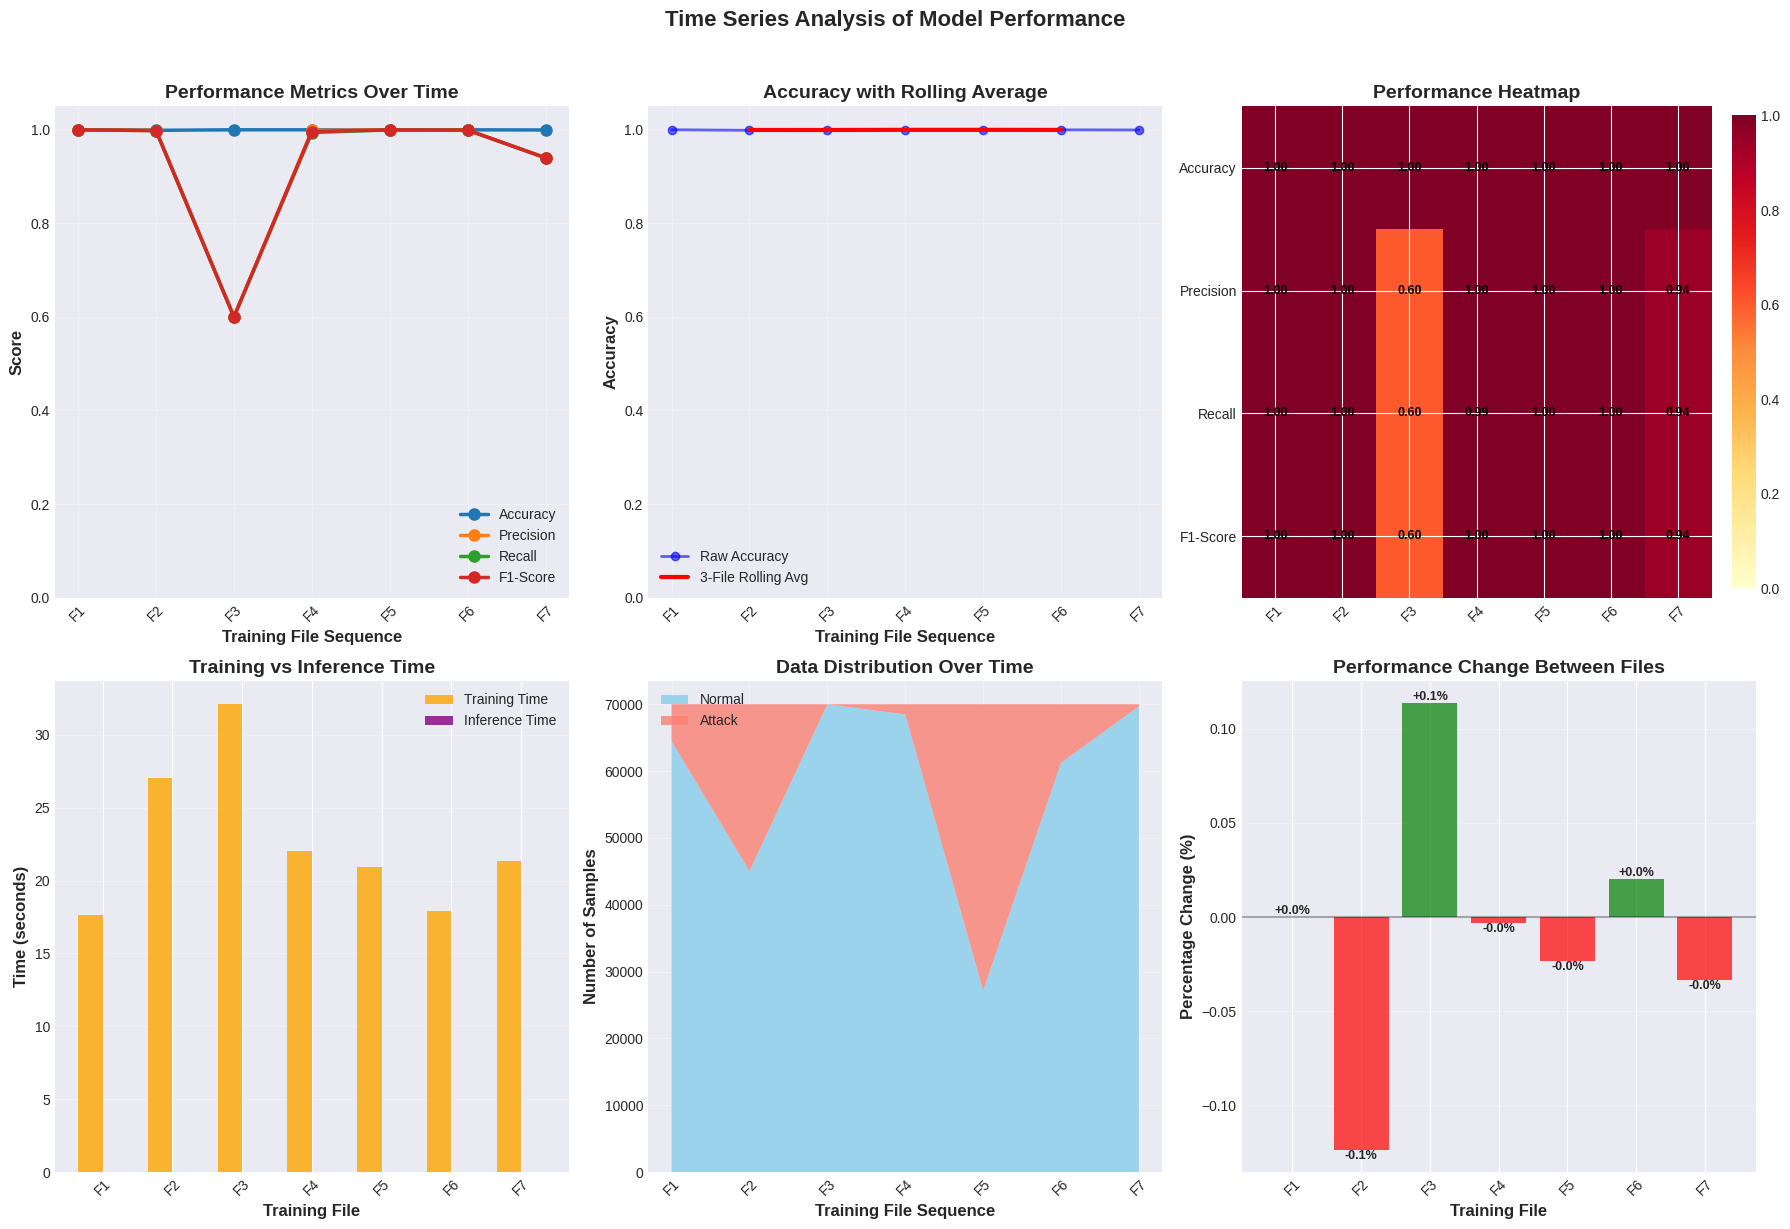

✅ Time series analysis saved: /content/results/time_series_analysis.png
3. Creating distribution analysis...


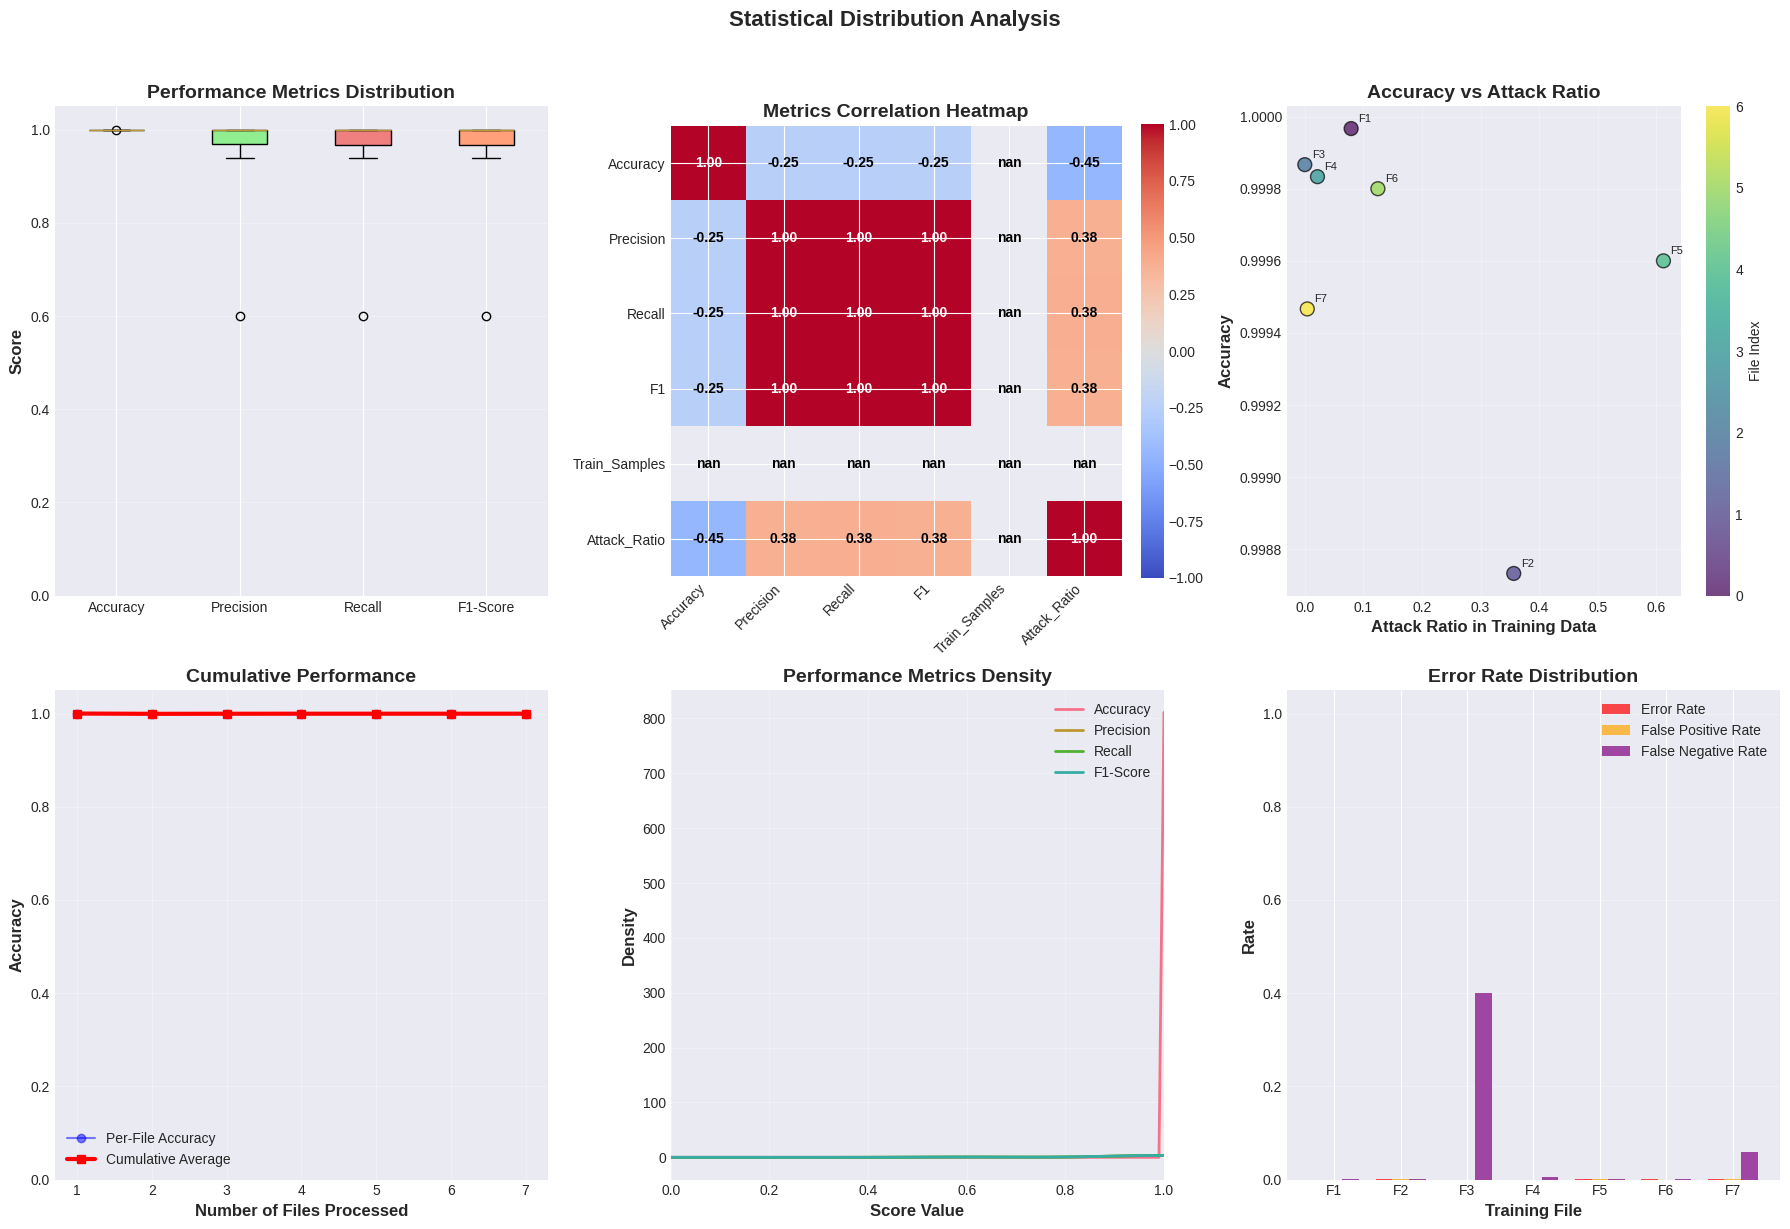

✅ Distribution analysis saved: /content/results/distribution_analysis.png
4. Creating quick overview...


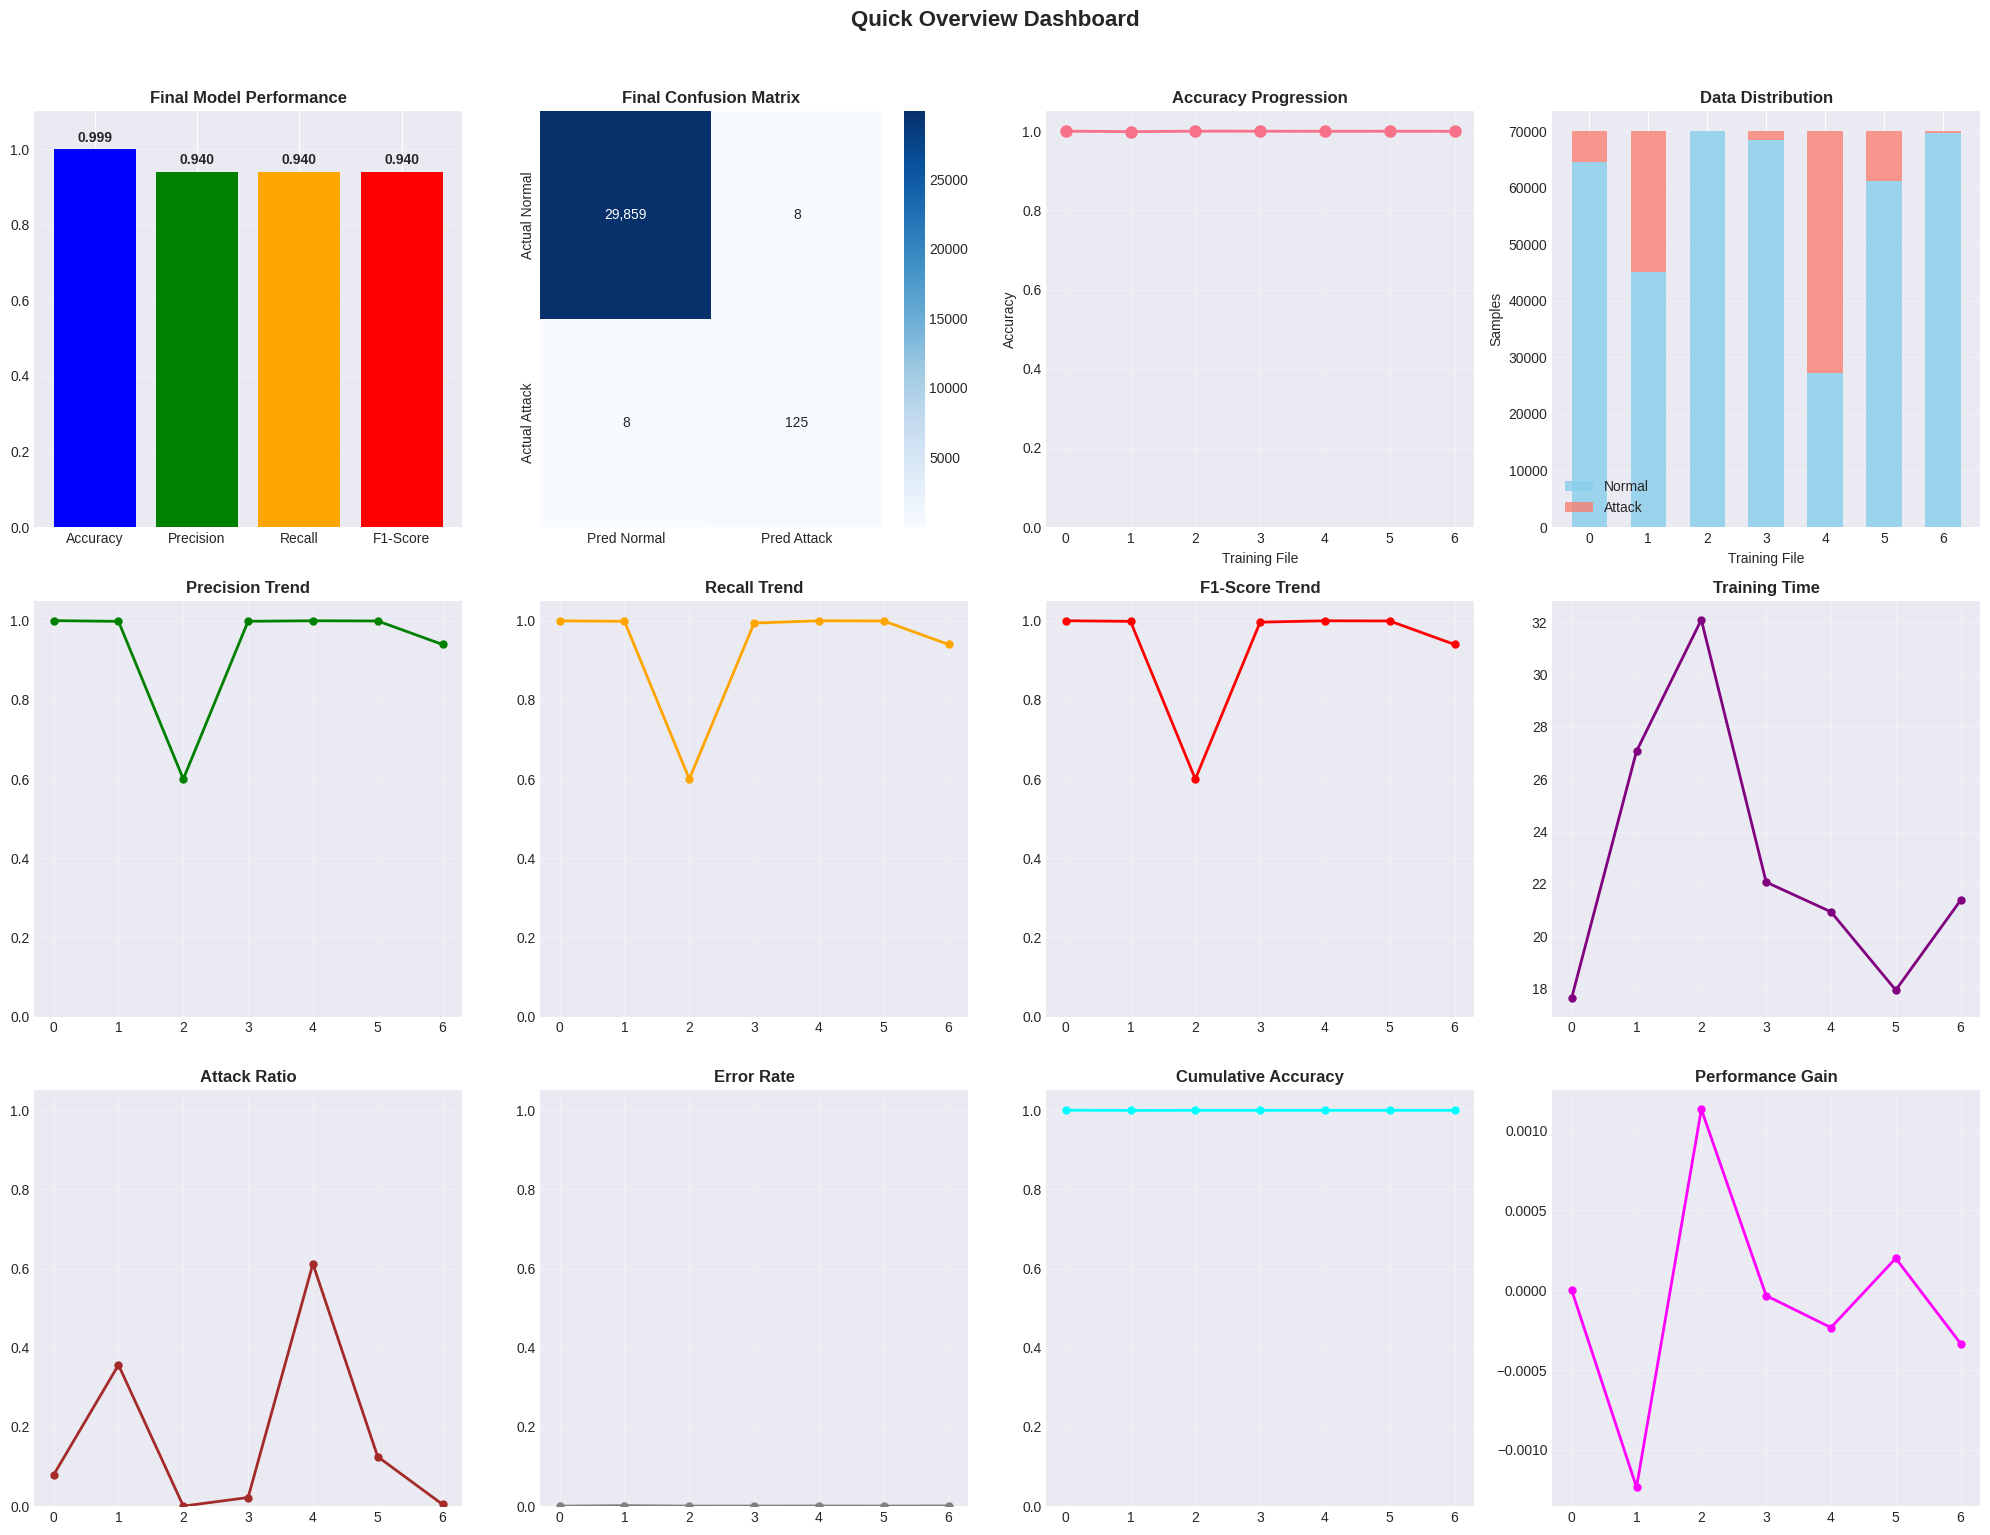

✅ Quick overview saved: /content/results/quick_overview.png

✅ ALL VISUALIZATIONS COMPLETE
📁 Results saved in: /content/results/
📊 View HTML dashboard: /content/results/performance_dashboard.html


In [105]:
# Install required packages
!pip install plotly scipy -q

# Run all visualizations (auto-detects latest results)
generate_all_visualizations()

# The following lines are redundant as generate_all_visualizations() already calls them.
# If you want to run individual visualizations, you would need to load 'results_data' explicitly first.
# quick_visualizations(results_data)
# plot_time_series_analysis(results_data)